# Size, direction, and model complexity: equities and FX since 2000

**Research question.** Does a directional–radial representation improve the density fit of daily financial observations relative to a Gaussian mixture, at similar numbers of free parameters? Does allowing size to depend on direction help beyond conditional independence within each group?

We run two **separate experiments**: a 50-stock equity panel and a ten-currency FX panel in nine independent coordinates. The period is **January 2000–October 30, 2026**. The first 60% is training, the next 20% validation, and the last 20% test. **The 2007–2009 crisis is inside training.** No PCA, learned encoder, feature subset search, volatility standardization, or winsorization is used.

The **primary comparison is the medium parameter budget**. Low/high budgets, the best configurations across the declared search, and a same-component linked/unlinked check answer distinct secondary questions. A winning test score describes this historical period; it does not prove true economic regimes or trading profitability.

The companion `size_direction_experiment.py` contains acquisition, model fitting, search, freezing, and evaluation. The notebook contains the experimental narrative, diagnostics, selection tables, figures, and conclusions. The old eight-feature notebook is archived under `outputs/size_direction_comparison/legacy_8feature_notebook.ipynb`.

In [1]:
from pathlib import Path
import sys, json, platform, hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits

roots = [Path.cwd(), Path.cwd()/'Thesis'/'GMM', Path.cwd()/'GMM']
ROOT = next((p for p in roots if (p/'size_direction_experiment.py').exists()), None)
assert ROOT is not None, 'Run from GMM, Thesis, or the workspace root.'
sys.path.insert(0, str(ROOT))
import size_direction_experiment as exp

# Download only when caches do not exist. Existing caches must match provenance hashes.
REFRESH_DATA = False
exp.acquire_data(refresh=REFRESH_DATA)
OUT = exp.OUTPUT
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi':110, 'axes.spines.top':False, 'axes.spines.right':False})
print('Python',platform.python_version(),'| NumPy',np.__version__,
      '| SciPy',exp.scipy.__version__,'| scikit-learn',exp.sklearn.__version__)
print('Fitting engine SHA256:',exp.engine_fingerprint())
print('All features remain in decimal-return units; no per-coordinate scaling.')

Matplotlib is building the font cache; this may take a moment.


Python 3.11.13 | NumPy 1.26.4 | SciPy 1.12.0 | scikit-learn 1.9.1
Fitting engine SHA256: fe6e48935d186d4a340dbb20a1873360205067af1126755575aa5e17d3f41aff
All features remain in decimal-return units; no per-coordinate scaling.


## 1. Data provenance, universe, and financial interpretation

**Equities:** ten established stocks in each of five descriptive groups. These labels are not historical index membership or time-varying GICS classifications. **PNC replaces BK before fitting**, because PNC had verified early-2000 public coverage and the BK endpoint did not. The universe was not selected using validation or test model scores.

Yahoo adjusted prices are obtained through [yfinance](https://ranaroussi.github.io/yfinance/reference/api/yfinance.download.html), with adjustments enabled and automatic repair disabled. A fixed surviving-stock cohort has **survivorship bias**; adjusted histories are current-vintage data, and corporate restructurings can change the economic identity of a price series. This is not a point-in-time investable-index backtest.

**FX:** EUR, USD, JPY, GBP, CHF, CAD, AUD, NZD, NOK, and SEK. The [ECB public download](https://www.ecb.europa.eu/stats/policy_and_exchange_rates/euro_reference_exchange_rates/html/index.en.html) quotes foreign-currency units per EUR. These are daily reference fixings, not tradeable bid/ask quotes, and cannot establish exploitable arbitrage.

Inputs are cached with source, coverage, retrieval timestamp, hashes, and acquisition settings. Prices must be positive, finite, complete, sorted, and unique. No instruments are silently substituted; missing values stop execution rather than being forward-filled. December 1999 observations provide the first January 2000 log return. The audit below flags extreme changes without deleting crisis observations.

In [2]:
for group, tickers in exp.GROUPS.items():
    print(f'{group}: '+', '.join(tickers))
print('FX currency order: '+', '.join(exp.CURRENCIES))
for filename in ['equity_adjusted_prices.csv','ecb_eur_quotes.csv']:
    provenance = json.loads((exp.DATA/filename).with_suffix('.provenance.json').read_text())
    print('\n'+filename)
    print('Coverage:',provenance['first_date'],'to',provenance['last_date'],
          '| rows:',provenance['rows'],'| retrieved:',provenance['retrieved_utc'])
    print('SHA256:',provenance['file_sha256'])

Technology: MSFT, AAPL, NVDA, ORCL, IBM, CSCO, INTC, QCOM, TXN, ADI
Finance: JPM, BAC, WFC, C, GS, MS, PNC, STT, AXP, SCHW
Healthcare: JNJ, PFE, MRK, ABT, AMGN, GILD, BMY, MDT, UNH, TMO
Consumer businesses: PG, KO, PEP, CL, KMB, WMT, COST, HD, LOW, NKE
Industrials: CAT, DE, HON, GE, UNP, UPS, FDX, EMR, ETN, ITW
FX currency order: EUR, USD, JPY, GBP, CHF, CAD, AUD, NZD, NOK, SEK

equity_adjusted_prices.csv
Coverage: 1999-12-27 to 2026-10-30 | rows: 6753 | retrieved: 2026-11-02T21:38:45.292636+00:00
SHA256: 4cde6e35d617059014d138feff120075dfe58d84cfa68dac52b97c7227de1ed1

ecb_eur_quotes.csv
Coverage: 1999-12-27 to 2026-10-30 | rows: 6871 | retrieved: 2026-11-02T21:38:46.442688+00:00
SHA256: 1bc6b165d4d9b4f6ba418d11e4906387af7844b34cd85ca045b6409682acb68a


## 2. Feature transformations and chronological splits

For stock $ i $, the modeled feature is the **unscaled decimal log return** $ x_{t,i}=\log P_{t,i}-\log P_{t-1,i} $. Neither the mean nor individual volatility is removed.

For FX, if $q_{t,i}$ is foreign-currency units per EUR, define currency log-strength changes $s_{t,i}=-\Delta\log q_{t,i}$, with EUR set to zero. Subtract the cross-currency mean to obtain $c_t$, then use a fixed Helmert matrix $H$ with orthonormal rows to construct $x_t=Hc_t$. This is a **basis change, not volatility scaling**. Pairwise currency-strength changes are differences $c_i-c_j$, so triangular identities hold by construction. Changing the original numeraire does not change $c_t$. Models live in nine full-rank contrast coordinates, avoiding a singular all-pairs FX covariance.

For either dataset, decompose each daily vector:
$$
r_t=\|x_t\|_2,\qquad u_t=x_t/r_t,\qquad y_t=\log r_t,\qquad x_t=e^{y_t}u_t.
$$
Both size and direction are retained exactly. Zero vectors have undefined direction and stop the run. Unit normalization removes a common positive daily multiplier from **direction only**. It does **not** eliminate the influence of individually volatile stocks. Imposed unit norm is not evidence that the original data naturally form a spherical shell.

Each dataset gets its own chronological 60/20/20 split, frozen after data validation; all three models use the same rows within that dataset. There are no forward outcomes or rolling inputs in the modeled features, so no label-maturity purge is needed. The reference calendars differ across equities and FX.

In [3]:
datasets = exp.load_data()
splits = exp.split_table(datasets)
display(splits)
splits.to_csv(OUT/'splits.csv',index=False)
assert all(pd.Timestamp('2008-09-15') in d.frame.index[:d.a] for d in datasets.values())
assert all(d.frame.index[d.a-1] > pd.Timestamp('2009-12-31') for d in datasets.values())
# Exact raw-return preservation and FX identity checks also run in load_data().
for name,data in datasets.items():
    y,u=exp.polar(data.train)
    np.testing.assert_allclose(np.exp(y[:,None])*u,data.train,atol=1e-14)
    np.testing.assert_allclose(np.linalg.norm(u,axis=1),1,atol=1e-12)
    print(name,':',data.frame.shape,'| training rank:',np.linalg.matrix_rank(data.train))
# Audit extremes without masking or winsorizing them; no model scores are used.
extremes=datasets['equities'].frame.stack().rename('log_return').to_frame()
extremes=extremes.loc[extremes.log_return.abs()>.30].reset_index()
extremes.columns=['date','ticker','log_return']
extremes['simple_return']=np.expm1(extremes.log_return)
extremes.to_csv(OUT/'equity_extreme_return_audit.csv',index=False)
print('Extreme equity changes flagged:',len(extremes),'(retained, not automatically repaired).')
print(extremes.sort_values('log_return').head(6).to_string(index=False))

,dataset,split,rows,dimensions,start,end
0,equities,train,4048,50,2000-01-03,2016-02-04
1,equities,validation,1350,50,2016-02-05,2021-06-16
2,equities,test,1350,50,2021-06-17,2026-10-30
3,fx,train,4120,9,2000-01-03,2016-02-08
4,fx,validation,1373,9,2016-02-09,2021-06-22
5,fx,test,1374,9,2021-06-23,2026-10-30


equities : (6748, 50) | training rank: 50
fx : (6867, 9) | training rank: 9
Extreme equity changes flagged: 24 (retained, not automatically repaired).
      date ticker  log_return  simple_return
2009-01-20    STT   -0.892504      -0.590371
2000-09-29   AAPL   -0.731248      -0.518692
2009-01-20    PNC   -0.534365      -0.413958
2009-02-27      C   -0.494696      -0.390244
2004-08-06   NVDA   -0.434383      -0.352336
2002-07-31   NVDA   -0.382009      -0.317511


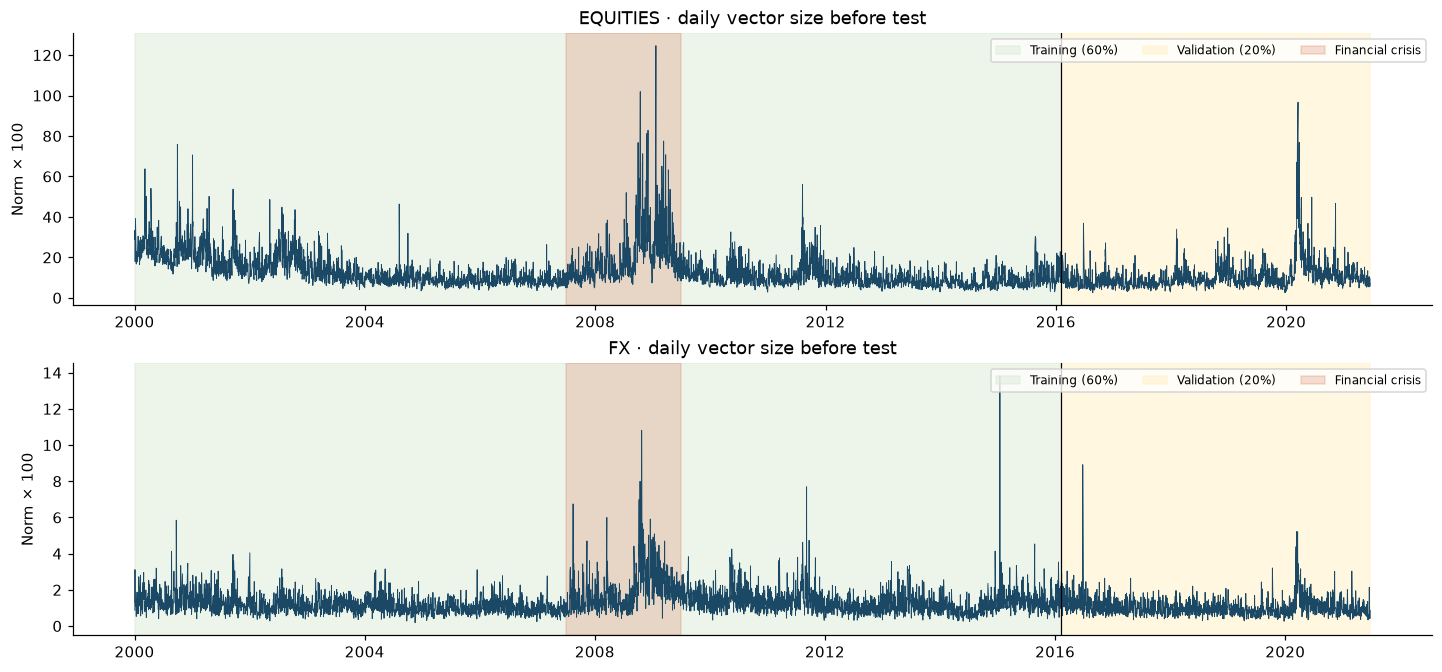

In [4]:
fig,axes=plt.subplots(2,1,figsize=(13,6),constrained_layout=True)
for ax,(name,data) in zip(axes,datasets.items()):
    frame=data.frame.iloc[:data.b]  # train + validation only, before test freeze
    norm=np.linalg.norm(frame.to_numpy(),axis=1)
    ax.plot(frame.index,100*norm,color='#1b4965',lw=.6)
    boundary=data.frame.index[data.a]
    ax.axvspan(frame.index[0],boundary,color='#d8ead3',alpha=.45,label='Training (60%)')
    ax.axvspan(boundary,frame.index[-1],color='#fff2cc',alpha=.6,label='Validation (20%)')
    ax.axvspan(pd.Timestamp('2007-07-01'),pd.Timestamp('2009-06-30'),color='#cf5c36',alpha=.2,label='Financial crisis')
    ax.axvline(boundary,color='black',lw=.8)
    ax.set(title=name.upper()+' · daily vector size before test',ylabel='Norm × 100')
    ax.legend(loc='upper right',fontsize=8,ncol=3)
plt.show()

## 3. Geometry diagnostics: correlations are not model inputs

A stock's **63-session return history** is a different object from a day's 50-stock vector. Within a diagnostic window, centering each stock history and normalizing that history to unit length gives vectors $v_i$ for which $v_i^\top v_j=\rho_{ij}$. Consequently, $\|v_i-v_j\|=\sqrt{2(1-\rho_{ij})}$, the correlation distance used in financial stock networks. [Mantegna](https://arxiv.org/abs/cond-mat/9802256)

This centering/history normalization is used **only to compute correlation diagnostics**; the 50 model features remain raw daily returns. Correlation matrices have positive-semidefinite and unit-diagonal constraints and are not treated as unconstrained sphere-valued observations.

We inspect mean correlation, leading correlation eigenvalue share, and angular concentration. Contrastive learning would add an encoder, augmentation choices, and a uniformity objective. Uniformity would be imposed by that objective, not discovered as a financial law; it is deferred here. [Wang & Isola](https://proceedings.mlr.press/v119/wang20k.html)

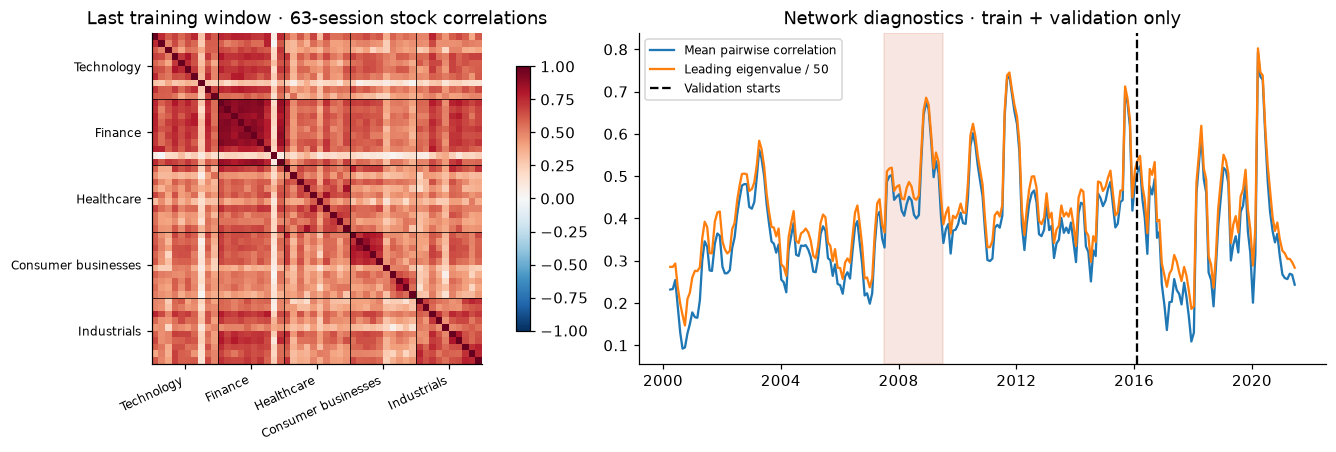

equities : mean resultant length = 0.0292 | angular second-moment largest eigenvalue = 0.2858
fx : mean resultant length = 0.0352 | angular second-moment largest eigenvalue = 0.2457
Correlation identity and spherical chord distances verified.


In [5]:
equity=datasets['equities']
window=equity.frame.iloc[equity.a-63:equity.a].to_numpy().T
centered=window-window.mean(axis=1,keepdims=True)
history_directions=centered/np.linalg.norm(centered,axis=1,keepdims=True)
correlation=np.corrcoef(window)
np.testing.assert_allclose(history_directions @ history_directions.T,correlation,atol=1e-12)
network_distance=np.sqrt(np.maximum(2*(1-correlation),0))
direct_distance=np.linalg.norm(history_directions[:,None,:]-history_directions[None,:,:],axis=2)
np.testing.assert_allclose(network_distance,direct_distance,atol=3e-8)

network=[]
for end in range(63,equity.b+1,21):
    c=equity.frame.iloc[end-63:end].corr().to_numpy()
    eigenvalues=np.linalg.eigvalsh(c)
    network.append(dict(date=equity.frame.index[end-1],
        mean_correlation=c[np.triu_indices(50,1)].mean(),
        leading_eigenvalue_share=eigenvalues[-1]/eigenvalues.sum()))
network=pd.DataFrame(network).set_index('date')
network.to_csv(OUT/'equity_network_diagnostics.csv')
fig,axes=plt.subplots(1,2,figsize=(14,4),constrained_layout=True)
image=axes[0].imshow(correlation,cmap='RdBu_r',vmin=-1,vmax=1)
axes[0].set_xticks(np.arange(4.5,50,10),list(exp.GROUPS),rotation=25,ha='right',fontsize=8)
axes[0].set_yticks(np.arange(4.5,50,10),list(exp.GROUPS),fontsize=8)
for edge in np.arange(9.5,50,10):
    axes[0].axhline(edge,color='black',lw=.5);axes[0].axvline(edge,color='black',lw=.5)
axes[0].set_title('Last training window · 63-session stock correlations')
fig.colorbar(image,ax=axes[0],shrink=.8)
axes[1].plot(network.index,network.mean_correlation,label='Mean pairwise correlation')
axes[1].plot(network.index,network.leading_eigenvalue_share,label='Leading eigenvalue / 50')
axes[1].axvline(equity.frame.index[equity.a],color='black',ls='--',label='Validation starts')
axes[1].axvspan(pd.Timestamp('2007-07-01'),pd.Timestamp('2009-06-30'),color='#cf5c36',alpha=.15)
axes[1].set_title('Network diagnostics · train + validation only')
axes[1].legend(fontsize=8)
plt.show()
for name,data in datasets.items():
    _,u=exp.polar(data.train)
    moments=u.T @ u/len(u)
    print(name,': mean resultant length =',round(np.linalg.norm(u.mean(axis=0)),4),
          '| angular second-moment largest eigenvalue =',round(np.linalg.eigvalsh(moments)[-1],4))
print('Correlation identity and spherical chord distances verified.')

## 4. Model definitions, libraries, and parameter counts

The GMM is fitted directly to the unscaled feature vector using scikit-learn. The cylindrical model is
$$
p(y,u)=\sum_{k=1}^{K}\pi_k\,\mathrm{vMF}(u;\mu_k,\kappa)
\,N(y;a_k+B_ku,\sigma^2),\qquad \|\mu_k\|=1.
$$

Variance and concentration are shared across components, as in the earlier model. **Unlinked** fixes \(B_k=0\); **linked** estimates it. Unlinked means size/direction independence **within** groups: shared group membership can still induce marginal dependence.

SciPy supplies normalized Gaussian/vMF distribution primitives, special functions, and numerical solvers. Custom EM logic handles joint responsibilities, weighted regression and the shared concentration update; fitting a standalone vMF mixture and a separate GMM would not fit this joint model. The companion module keeps this code out of the experiment narrative. Synthetic and numerical checks below independently exercise its restrictions and transformations.

To compare densities with respect to the same measure, apply
$$
\log p_X(x)=\log p_{Y,U}(y,u)-d\,y.
$$
The GMM already evaluates density in decimal-return coordinates. FX density is defined in its fixed orthonormal nine-dimensional contrast space. **Do not compare absolute density values between the 50-dimensional equity and nine-dimensional FX experiments.** Nats use natural logarithms; higher mean log density is better, not a probability or trading return.

| Family | Free parameters |
|---|---:|
| GMM spherical covariance | \(K(d+2)-1\) |
| GMM diagonal covariance | \(K(2d+1)-1\) |
| GMM tied covariance | \(K(d+1)-1+d(d+1)/2\) |
| GMM full covariance | \(K-1+Kd+Kd(d+1)/2\) |
| Unlinked cylindrical | \(K(d+1)+1\) |
| Linked cylindrical | \(K(2d+1)+1\) |

Counts include weight constraints and \(d-1\) degrees of freedom per unit direction. Ridge regularization does **not** reduce the count. Diagonal, spherical, tied and full covariance structures provide explicit complexity control. Sparse-precision graphical lasso and factor-analyzer mixtures are useful extensions, deferred to keep this experiment auditable.

Weighted regressions use SciPy Cholesky solves only when a reciprocal-condition estimate is at least $10^{-7}$; poorly conditioned or rank-deficient systems fall back to the original SVD least-squares solver. No coefficient penalty is introduced. Reference-solver agreement on actual training weights and the cache provenance checks are recorded in `regression_solver_verification.json`; the observed maximum coefficient difference was below $6\times10^{-13}$.

## 5. Numerical checks and synthetic recovery

Run the companion checks before selecting financial models: raw-return preservation; crisis-in-training splits; FX identities; invertible polar coordinates; finite-difference Jacobians in 9 and 50 dimensions; SciPy vMF density agreement; concentration recovery; normalized posteriors; monotone cylindrical EM; synthetic linked and zero-link examples; parameter matching; paired bootstrap behavior; and GMM density agreement with an independent Gaussian evaluation. Full-rank regression agreement and rank-deficient SVD fallback are checked as well.

In [6]:
import unittest
import test_size_direction_experiment as checks
suite=unittest.defaultTestLoader.loadTestsFromModule(checks)
verification=unittest.TextTestRunner(verbosity=2).run(suite)
assert verification.wasSuccessful()

test_data_splits_include_crisis_in_training_and_no_scaling (test_size_direction_experiment.ExperimentChecks.test_data_splits_include_crisis_in_training_and_no_scaling) ... ok
test_paired_bootstrap_and_gaussian_density (test_size_direction_experiment.ExperimentChecks.test_paired_bootstrap_and_gaussian_density) ... ok
test_parallel_refit_preserves_deduplicated_architectures (test_size_direction_experiment.ExperimentChecks.test_parallel_refit_preserves_deduplicated_architectures) ... 

synthetic: refit gmm_k01_diag_1e-08: 10/10 accepted


ok
test_parameter_counts_and_budget_selection (test_size_direction_experiment.ExperimentChecks.test_parameter_counts_and_budget_selection) ... 

synthetic: refit gmm_k02_diag_1e-08: 10/10 accepted


ok
test_polar_and_jacobian (test_size_direction_experiment.ExperimentChecks.test_polar_and_jacobian) ... ok
test_selection_is_validation_only_and_ties (test_size_direction_experiment.ExperimentChecks.test_selection_is_validation_only_and_ties) ... ok
test_synthetic_link_and_null (test_size_direction_experiment.ExperimentChecks.test_synthetic_link_and_null) ... ok
test_two_component_joint_mixture_recovers_a_real_link (test_size_direction_experiment.ExperimentChecks.test_two_component_joint_mixture_recovers_a_real_link) ... ok
test_vmf_density_and_concentration (test_size_direction_experiment.ExperimentChecks.test_vmf_density_and_concentration) ... ok
test_weighted_regression_matches_reference_and_rank_deficient_fallback (test_size_direction_experiment.ExperimentChecks.test_weighted_regression_matches_reference_and_rank_deficient_fallback) ... ok

----------------------------------------------------------------------
Ran 10 tests in 2.926s

OK


## 6. Training and validation search — test scores unavailable

The declared grid has **280 configurations per dataset**: 20 component counts × four GMM covariance structures × three ridge values, plus 20 linked and 20 unlinked models. Every configuration gets ten reproducible starts (5,600 starts overall), seed 42, at most 500 EM iterations, and a \(10^{-6}\) mean training-likelihood tolerance.

Training selects the best converged, non-collapsed start. Validation selects configurations. Same-\(K\) unlinked solutions initialize the tenth linked start. Weighted group membership below five training observations, the log-size variance floor \(10^{-6}\), the concentration ceiling \(10^4\), and nonconvergence are explicitly recorded and excluded. Cylindrical likelihood must be monotone; scikit-learn's ridge GMM is allowed its documented numerical behavior, with warnings retained per start.

K-means initializations are reproducibly reused across GMM covariance/ridge choices to avoid repeating identical initialization work. They do not standardize input features. GMM fitting itself remains scikit-learn's implementation.

The search function accepts **only training and validation arrays**. Checkpoints are keyed by exact input hashes, fitting implementation/settings, and dependency versions; completed fits are loaded only when those match. Failed fits remain visible in the trial ledger. Model-level per-start diagnostics are stored with every checkpoint. Re-running this cell reuses valid results rather than silently shrinking the grid.

equities: completed K=1/20 (14/280 configurations)
equities: completed K=2/20 (28/280 configurations)
equities: completed K=3/20 (42/280 configurations)
equities: completed K=4/20 (56/280 configurations)
equities: completed K=5/20 (70/280 configurations)
equities: completed K=6/20 (84/280 configurations)
equities: completed K=7/20 (98/280 configurations)
equities: completed K=8/20 (112/280 configurations)
equities: completed K=9/20 (126/280 configurations)
equities: completed K=10/20 (140/280 configurations)
equities: completed K=11/20 (154/280 configurations)
equities: completed K=12/20 (168/280 configurations)
equities: completed K=13/20 (182/280 configurations)
equities: completed K=14/20 (196/280 configurations)
equities: completed K=15/20 (210/280 configurations)
equities: completed K=16/20 (224/280 configurations)
equities: completed K=17/20 (238/280 configurations)
equities: completed K=18/20 (252/280 configurations)
equities: completed K=19/20 (266/280 configurations)
equities:

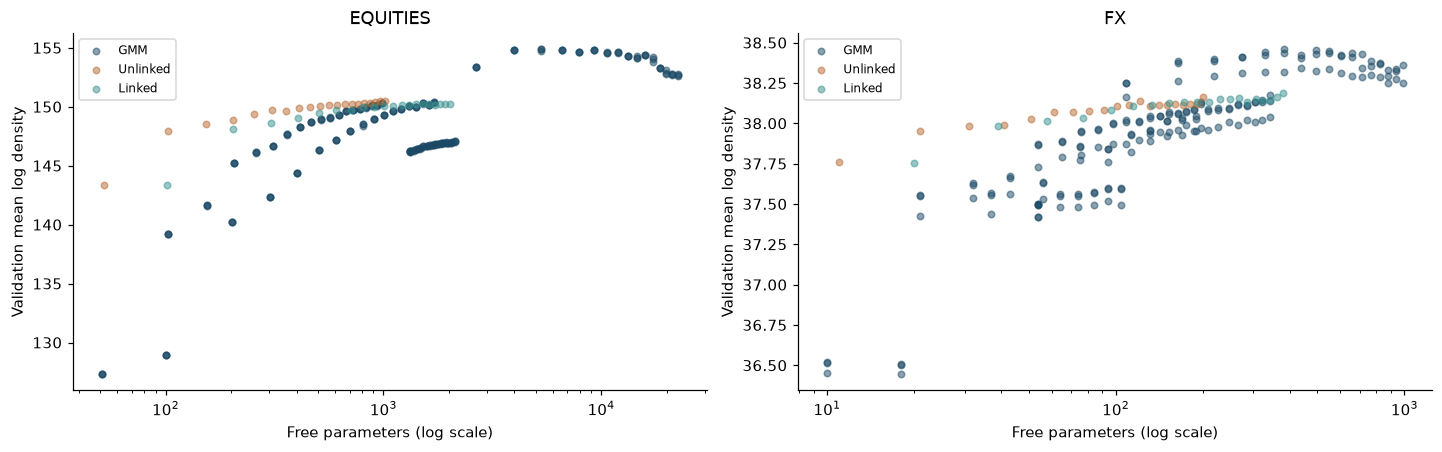

In [7]:
searches={}
for name,data in datasets.items():
    trials,cache=exp.run_search(name,data.train,data.validation)
    searches[name]=(trials,cache)
    assert len(trials)==280
    print(name,':',int(trials.validation_mean_loglik.notna().sum()),'/ 280 admissible configurations',
          '| rejected starts:',int(trials.rejected_starts.sum()))
    print('Trial ledger:',OUT/f'{name}_validation_trials.csv')

fig,axes=plt.subplots(1,2,figsize=(13,4),constrained_layout=True)
colors={'GMM':'#1b4965','Unlinked':'#b86b32','Linked':'#38918e'}
for ax,(name,(trials,_)) in zip(axes,searches.items()):
    for family,color in colors.items():
        good=trials.loc[(trials.family==family)&trials.validation_mean_loglik.notna()]
        ax.scatter(good.parameters,good.validation_mean_loglik,s=18,alpha=.5,color=color,label=family)
    ax.set(xscale='log',xlabel='Free parameters (log scale)',ylabel='Validation mean log density',title=name.upper())
    ax.legend(fontsize=8)
plt.show()

## 7. Freeze validation-selected configurations

**Matched complexity:** for reference component counts \(K_0=3,6,9\), set \(B=K_0(2d+1)-1\) and admit counts in \([B,\lfloor1.10B\rfloor]\). Within each band select the validation winner of each family. The medium band is primary. Full-covariance configurations that cannot fit a band remain eligible in the unrestricted comparison.

**Best within the search:** independently choose each family's validation winner across its full declared grid. These models can have very different parameter counts.

**Same components:** among component counts with admissible fits in all three families, choose one \(K\) maximizing the average linked/unlinked validation likelihood, then select the GMM specification at that same \(K\). This tests the link restriction at fixed component count; it is not parameter matched.

Validation-score ties within \(10^{-6}\) nats/observation prefer fewer parameters, then fewer components, then fixed configuration order. Each matched group must have at most a 10% max/min parameter spread. No test scores enter these choices. The manifest below freezes configurations, split dates, input hashes, and engine identity before test evaluation.

In [8]:
selected,freeze=exp.freeze_selections(searches,datasets)
assert not freeze['test_used_for_selection']
for (name,view),group in selected.groupby(['dataset','view']):
    if view.startswith('budget'):
        assert group.parameters.max()/group.parameters.min() <= 1.10+1e-12
    elif view=='same_components':
        assert group.k.nunique()==1
print('Freeze SHA256:',freeze['freeze_sha256'])
display(selected[['dataset','view','family','k','covariance','regularization','parameters','validation_mean_loglik']]
        .style.format({'validation_mean_loglik':'{:.4f}','regularization':'{:.0e}'}))
print('Frozen manifest:',OUT/'frozen_selections.json')

Freeze SHA256: 7d55d497d7446147596e8a0f7e10d8c369c5ade1be54d27db75fe9f6016b5158


,dataset,view,family,k,covariance,regularization,parameters,validation_mean_loglik
0,equities,budget_low,GMM,6,spherical,1e-08,311,146.6571
1,equities,budget_low,Unlinked,6,,0e+00,307,149.6928
2,equities,budget_low,Linked,3,,0e+00,304,148.6188
3,equities,budget_medium,GMM,12,spherical,1e-08,623,149.3263
4,equities,budget_medium,Unlinked,13,,0e+00,664,150.1956
5,equities,budget_medium,Linked,6,,0e+00,607,149.7562
6,equities,budget_high,GMM,19,spherical,1e-06,987,150.3026
7,equities,budget_high,Unlinked,19,,0e+00,970,150.4547
8,equities,budget_high,Linked,9,,0e+00,910,150.0060
9,equities,unrestricted,GMM,4,full,1e-07,5303,154.8565


Frozen manifest: /Users/shashwatroy/VSCode Projects/Thesis/GMM/outputs/size_direction_2000/frozen_selections.json


## 8. Refit on the first 80%, then evaluate the final 20%

All selected architectures are refitted on **training + validation** before any test likelihood is evaluated. Architectures selected in multiple views share one refit. Refit failure stops evaluation instead of substituting a model based on test performance.

The main metric is mean test log density in nats per observation. Confidence intervals use 1,500 **paired circular moving-block** resamples of the same test dates, with block lengths 5, **20 (primary)**, and 60. These pointwise intervals condition on the selected/refitted models; they do not include training uncertainty or multiple-comparison adjustment. Earlier research has studied overlapping historical calendar periods, so this is a holdout from the present selection procedure, not a claim of globally untouched history.

The single results CSV contains every comparison view, parameter count, selected component count, refit diagnostics, and all interval sensitivities. Daily test log densities are retained separately for auditing.

In [9]:
results,fitted=exp.final_evaluation(datasets,searches)
assert len(results)==30
# One final results table; medium budget is the predeclared primary view.
shown=results[['dataset','view','family','components','parameters','test_mean_loglik',
               'gain_vs_gmm','gain_vs_unlinked','accepted_refit_starts','rejected_refit_starts']].copy()
shown['gain vs GMM · 95% CI']=results.apply(
    lambda r:f"[{r.gain_vs_gmm_L20_low:+.4f}, {r.gain_vs_gmm_L20_high:+.4f}]",axis=1)
shown['gain vs unlinked · 95% CI']=results.apply(
    lambda r:f"[{r.gain_vs_unlinked_L20_low:+.4f}, {r.gain_vs_unlinked_L20_high:+.4f}]",axis=1)
display(shown.style.format({c:'{:+.4f}' for c in ['gain_vs_gmm','gain_vs_unlinked']})
    .format({'test_mean_loglik':'{:.4f}'})
    .apply(lambda row:['background-color: #e8f3f1' if row['view']=='budget_medium' else '' for _ in row],axis=1)
    .set_caption('Final test results · medium parameter budget is primary · paired 20-session intervals'))
print('Results:',OUT/'test_results.csv')
print('Intervals for 5/60-session blocks and numeric bounds are included in that same CSV.')

,dataset,view,family,components,parameters,test_mean_loglik,gain_vs_gmm,gain_vs_unlinked,accepted_refit_starts,rejected_refit_starts,gain vs GMM · 95% CI,gain vs unlinked · 95% CI
0,equities,budget_low,GMM,6,311,138.2623,0.000000,-2.652254,10,0,"[+0.0000, +0.0000]","[-2.9746, -2.3127]"
1,equities,budget_low,Unlinked,6,307,140.9146,2.652254,0.000000,10,0,"[+2.3127, +2.9746]","[+0.0000, +0.0000]"
2,equities,budget_low,Linked,3,304,139.8418,1.579431,-1.072823,10,0,"[+1.3002, +1.8474]","[-1.2349, -0.9068]"
3,equities,budget_medium,GMM,12,623,140.3747,0.000000,-1.169282,7,3,"[+0.0000, +0.0000]","[-1.5645, -0.7565]"
4,equities,budget_medium,Unlinked,13,664,141.5440,1.169282,0.000000,10,0,"[+0.7565, +1.5645]","[+0.0000, +0.0000]"
5,equities,budget_medium,Linked,6,607,140.9293,0.554588,-0.614694,10,0,"[+0.1330, +0.9420]","[-0.7632, -0.4774]"
6,equities,budget_high,GMM,19,987,141.5036,0.000000,-0.223892,3,7,"[+0.0000, +0.0000]","[-0.5521, +0.1238]"
7,equities,budget_high,Unlinked,19,970,141.7275,0.223892,0.000000,10,0,"[-0.1238, +0.5521]","[+0.0000, +0.0000]"
8,equities,budget_high,Linked,9,910,141.2130,-0.290570,-0.514462,10,0,"[-0.6473, +0.0511]","[-0.6580, -0.3860]"
9,equities,unrestricted,GMM,4,5303,146.7212,0.000000,4.923033,10,0,"[+0.0000, +0.0000]","[+4.4056, +5.4897]"


Results: /Users/shashwatroy/VSCode Projects/Thesis/GMM/outputs/size_direction_2000/test_results.csv
Intervals for 5/60-session blocks and numeric bounds are included in that same CSV.


## 9. Interpretability: profiles and the size–direction link

For the **primary medium-budget models**, show posterior-weighted empirical mean returns from the refit period (first 80%). Equity profiles display the five economic-group averages, but all 50 stocks remain model inputs. FX profiles map the nine contrasts back to centered strengths of the ten named currencies. Rows are ordered within each model by posterior-weighted vector size; they do not identify matching economic states across models.

Linked coefficients describe the conditional mean of log size. Equity plots show mean coefficients within each economic group solely for readability; complete per-stock coefficients are exported. FX coefficients are mapped back to currency-strength coordinates. Directions are constrained and correlated, so these are fitted associations, not causal effects or independent interventions.

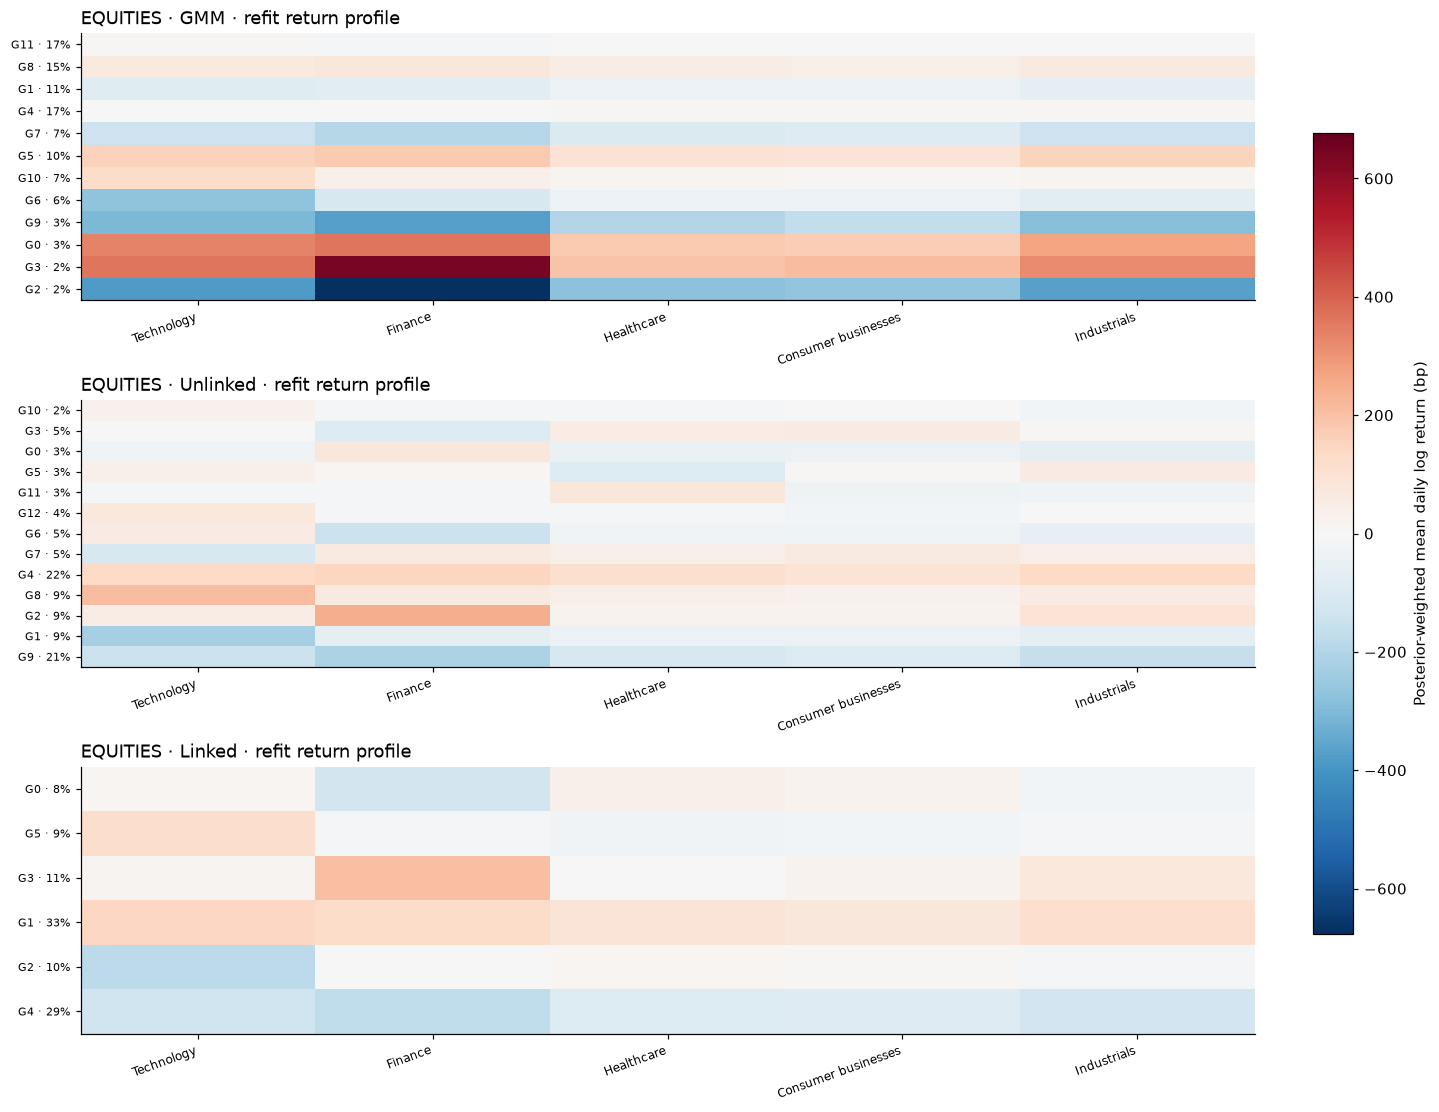

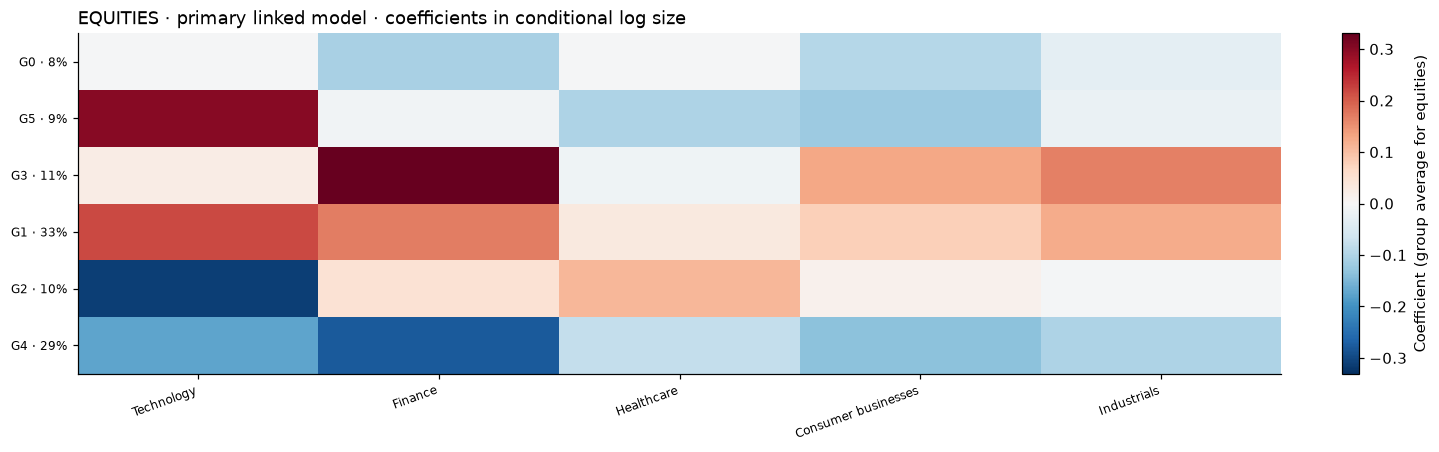

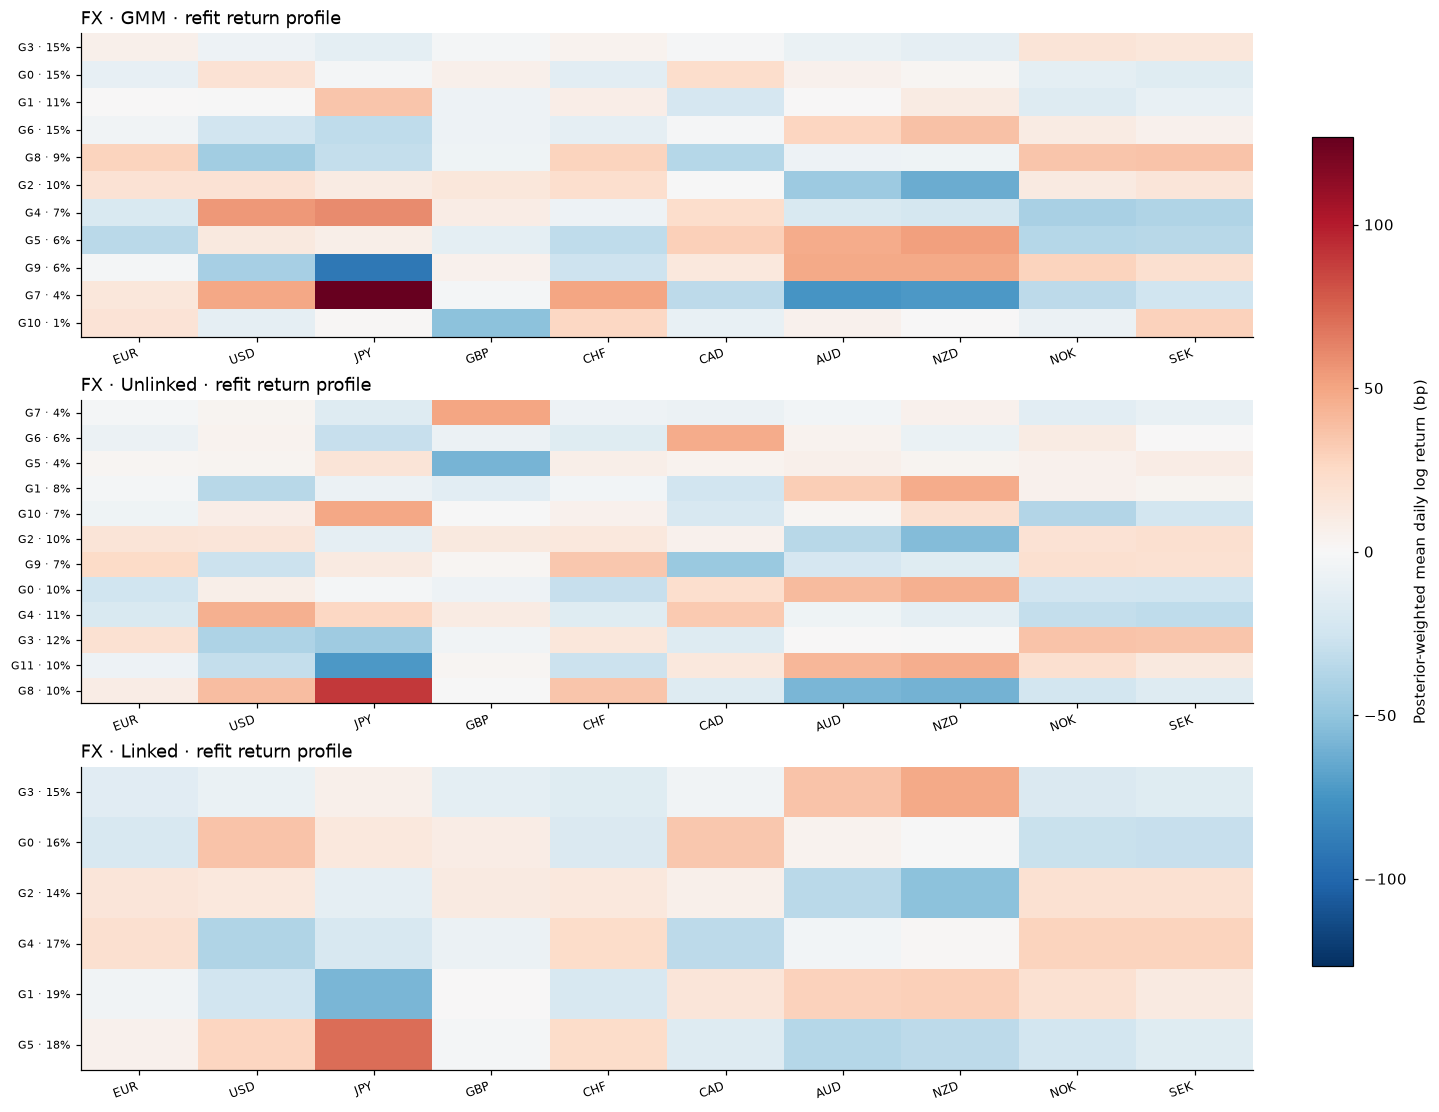

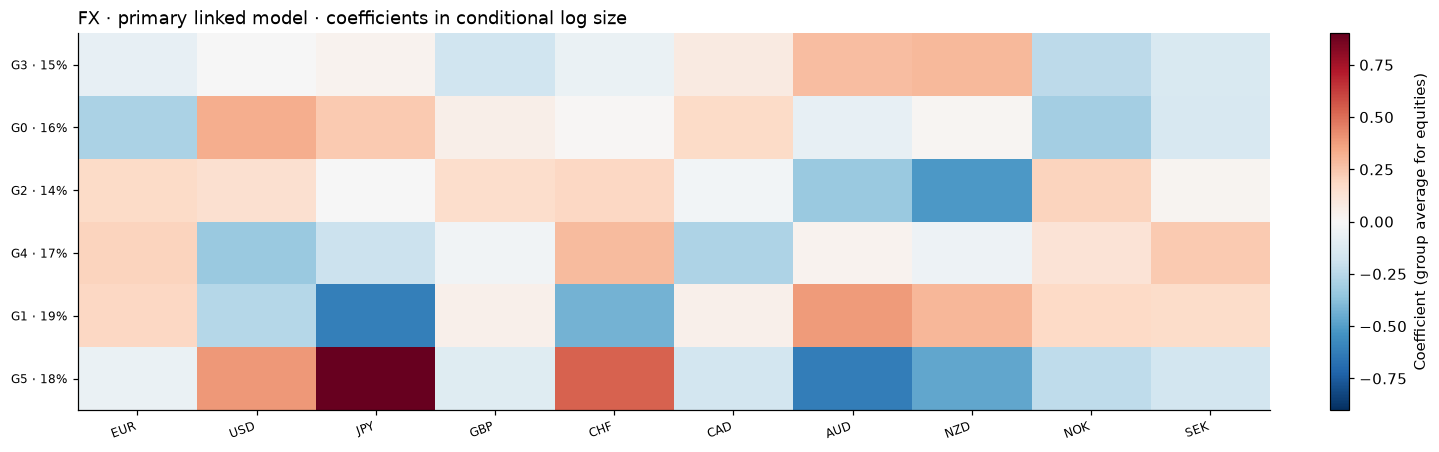

In [10]:
coefficient_exports=[]
for name,data in datasets.items():
    primary=selected.loc[(selected.dataset==name)&(selected.view=='budget_medium')]
    x=data.development
    represented=x if name=='equities' else x @ data.basis
    labels=list(exp.GROUPS) if name=='equities' else exp.CURRENCIES
    def grouped(matrix):
        return np.column_stack([matrix[:,i:i+10].mean(axis=1) for i in range(0,50,10)]) if name=='equities' else matrix
    panels=[]
    for choice in primary.itertuples():
        record=fitted[name][choice.candidate]
        with threadpool_limits(limits=1):q=exp.posterior_model(x,record)
        mass=q.sum(axis=0)
        means=(q.T @ represented)/mass[:,None]
        mean_size=q.T @ np.linalg.norm(x,axis=1)/mass
        order=np.argsort(mean_size)
        profile=grouped(means)[order]*10000
        rows=[f'G{j} · {mass[j]/len(x):.0%}' for j in order]
        panels.append((choice.family,profile,rows,order,record))
    limit=max(abs(p[1]).max() for p in panels)
    fig,axes=plt.subplots(3,1,figsize=(13,10),constrained_layout=True)
    for ax,(family,profile,rows,_,_) in zip(axes,panels):
        image=ax.imshow(profile,cmap='RdBu_r',vmin=-limit,vmax=limit,aspect='auto')
        ax.set_xticks(np.arange(len(labels)),labels,rotation=20,ha='right',fontsize=8)
        ax.set_yticks(np.arange(len(rows)),rows,fontsize=7)
        ax.set_title(name.upper()+' · '+family+' · refit return profile',loc='left')
    fig.colorbar(image,ax=axes,label='Posterior-weighted mean daily log return (bp)',shrink=.8)
    plt.show()
    _,_,rows,order,record=next(p for p in panels if p[0]=='Linked')
    beta=record['fit']['coef'][:,1:]
    mapped=beta if name=='equities' else beta @ data.basis
    plot_beta=grouped(mapped)[order]
    fig,ax=plt.subplots(figsize=(13,4),constrained_layout=True)
    limit=max(abs(plot_beta).max(),1e-8)
    image=ax.imshow(plot_beta,cmap='RdBu_r',vmin=-limit,vmax=limit,aspect='auto')
    ax.set_xticks(np.arange(len(labels)),labels,rotation=20,ha='right',fontsize=8)
    ax.set_yticks(np.arange(len(rows)),rows,fontsize=8)
    ax.set_title(name.upper()+' · primary linked model · coefficients in conditional log size',loc='left')
    fig.colorbar(image,ax=ax,label='Coefficient (group average for equities)')
    plt.show()
    names=exp.STOCKS if name=='equities' else exp.CURRENCIES
    for component in range(len(mapped)):
        for feature,coefficient in zip(names,mapped[component]):
            coefficient_exports.append(dict(dataset=name,component=component,feature=feature,coefficient=coefficient))
pd.DataFrame(coefficient_exports).to_csv(OUT/'primary_link_coefficients.csv',index=False)

## 10. Brief conclusions and limits

The conclusions distinguish **matched-parameter performance**, **best configurations within the search**, and the **same-component link restriction**. They are generated after all choices are frozen. No change is made to features, budgets, component counts, or fitting settings in response to the test results.

In [11]:
conclusions=[]
for name in datasets:
    r=results.loc[results.dataset==name]
    primary=r.loc[r.view=='budget_medium'].set_index('family')
    unrestricted=r.loc[r.view=='unrestricted'].set_index('family')
    nested=r.loc[r.view=='same_components'].set_index('family')
    winner=primary.test_mean_loglik.idxmax()
    overall=unrestricted.test_mean_loglik.idxmax()
    link=nested.loc['Linked']
    low,high=link.gain_vs_unlinked_L20_low,link.gain_vs_unlinked_L20_high
    assessment=('supports a positive link gain' if low>0 else 'supports a negative link gain' if high<0
                else 'does not resolve the sign of the link gain')
    signs=[(link[f'gain_vs_unlinked_L{b}_low']>0,link[f'gain_vs_unlinked_L{b}_high']<0) for b in (5,20,60)]
    sensitivity=('consistent across block lengths' if len(set(signs))==1 else 'sensitive to block length')
    text=(f"**{name.upper()}.** At the primary matched parameter budget, **{winner}** has the highest test mean log density "
          f"(parameter counts {', '.join(f'{family}: {int(row.parameters)}' for family,row in primary.iterrows())}). "
          f"The unrestricted validation-selected comparison favors **{overall}** on test. "
          f"At the jointly validation-selected K={int(link.components)}, the linked-minus-unlinked gain is "
          f"**{link.gain_vs_unlinked:+.4f} nats/observation**, with paired 95% interval "
          f"[{low:+.4f}, {high:+.4f}]; this {assessment}. The interval conclusion is {sensitivity}. "
          "The 2008 crisis is in training. Findings concern historical density fit, not profitability or proof of natural hyperspherical geometry.")
    assert len(text.split())<=170
    display(Markdown(text));conclusions.append(text)
(OUT/'conclusions.md').write_text('\n\n'.join(conclusions)+'\n')
print('Completed: two datasets, 560 searched configurations, validation-only selection, 30 final comparison rows.')
print('Manifest hash:',freeze['freeze_sha256'])
print('Validation trials, split dates, per-start diagnostics, frozen selections, test scores, and provenance retained.')

**EQUITIES.** At the primary matched parameter budget, **Unlinked** has the highest test mean log density (parameter counts GMM: 623, Unlinked: 664, Linked: 607). The unrestricted validation-selected comparison favors **GMM** on test. At the jointly validation-selected K=19, the linked-minus-unlinked gain is **-0.2043 nats/observation**, with paired 95% interval [-0.3202, -0.0901]; this supports a negative link gain. The interval conclusion is consistent across block lengths. The 2008 crisis is in training. Findings concern historical density fit, not profitability or proof of natural hyperspherical geometry.

**FX.** At the primary matched parameter budget, **Linked** has the highest test mean log density (parameter counts GMM: 120, Unlinked: 121, Linked: 115). The unrestricted validation-selected comparison favors **GMM** on test. At the jointly validation-selected K=12, the linked-minus-unlinked gain is **+0.0512 nats/observation**, with paired 95% interval [+0.0282, +0.0748]; this supports a positive link gain. The interval conclusion is consistent across block lengths. The 2008 crisis is in training. Findings concern historical density fit, not profitability or proof of natural hyperspherical geometry.

Completed: two datasets, 560 searched configurations, validation-only selection, 30 final comparison rows.
Manifest hash: 7d55d497d7446147596e8a0f7e10d8c369c5ade1be54d27db75fe9f6016b5158
Validation trials, split dates, per-start diagnostics, frozen selections, test scores, and provenance retained.


## 11. Follow-up: component-specific variance and concentration

This extension compares **nine model families**: GMM plus linked/unlinked versions of four sharing structures. “One component-specific parameter” has two distinct interpretations, so both are implemented.

| Sharing specification | Gaussian variance | vMF concentration | Unlinked parameters | Linked parameters |
|---|---|---|---:|---:|
| Original shared | $\sigma^2$ | $\kappa$ | $K(d+1)+1$ | $K(2d+1)+1$ |
| Separate variance | $\sigma_k^2$ | $\kappa$ | $K(d+2)$ | $K(2d+2)$ |
| Separate concentration | $\sigma^2$ | $\kappa_k$ | $K(d+2)$ | $K(2d+2)$ |
| Both separate | $\sigma_k^2$ | $\kappa_k$ | $K(d+3)-1$ | $K(2d+3)-1$ |

Every shared scalar changed to $K$ component-specific scalars adds $K-1$ parameters. The Gaussian models log size, so its variance is scalar; the vMF concentration controls angular dispersion.

For responsibilities $r_{ik}$ and $N_k=\sum_i r_{ik}$, the new updates are
\[
\sigma_k^2=\frac{\sum_i r_{ik}(y_i-a_k-B_ku_i)^2}{N_k},\qquad
A_d(\kappa_k)=\frac{\|\sum_i r_{ik}u_i\|}{N_k},
\]
where $A_d(\kappa)=I_{d/2}(\kappa)/I_{d/2-1}(\kappa)$. Shared variance pools residual sums over all observations; shared concentration solves $A_d(\kappa)=\sum_k\|\sum_i r_{ik}u_i\|/n$. The remaining EM updates are unchanged. Variance floors, concentration caps, effective-membership rejection and monotonicity checks apply to every component.

**Protocol:** retain the exact inputs and 60/20/20 splits. Search $K=1,\ldots,20$ separately for each new family, ten starts, seed 42, 500 iterations, $10^{-6}$ mean-likelihood tolerance. Choose starts by training likelihood and configurations by validation likelihood. Linked fitting includes the same-specification unlinked zero-link start. Original selected models and their refits are reused exactly. Freeze every new choice before refitting on training + validation, then score all models identically.

The three original parameter bands and unrestricted view apply to each new family. The same-component view retains the previously frozen anchors (**equities K=19, FX K=12**); this avoids changing the reference comparison. If a family has no admissible validation candidate or its selected refit fails, report it as unavailable rather than changing the budget or choosing through test scores.

This is an **exploratory follow-up**: the test dates have already been inspected. The new hyperparameters still use validation only, but the extension itself is informed by earlier results.

**Budget feasibility:** the original FX bands cannot contain every new family at an integer K. Low-budget separate-variance/separate-concentration unlinked models jump from 55 to 66 parameters, outside [56,61]. The fully separate linked model has 62, 125, or 188 parameters at K=3,6,9, just above the respective band ceilings 61,124,187. These five cells are explicitly unavailable; all nine families are still compared in the unrestricted and fixed-K views. The bands are not widened after viewing performance.

In [12]:
import size_direction_sharing as sharing
import size_direction_sharing_report as sharing_report
import test_size_direction_sharing
sharing_suite=unittest.defaultTestLoader.loadTestsFromModule(test_size_direction_sharing)
sharing_checks=unittest.TextTestRunner(verbosity=2).run(sharing_suite)
assert sharing_checks.wasSuccessful()
sharing_trials=sharing.search_all(datasets,workers=6)
sharing_selected,sharing_freeze=sharing.freeze(sharing_trials,datasets)
display(sharing_selected[['dataset','view','family','k','parameters','validation_mean_loglik','status']])
print('Sharing freeze:',sharing_freeze['freeze_sha256'])

test_counts (test_size_direction_sharing.SharingChecks.test_counts) ... ok
test_normalizers (test_size_direction_sharing.SharingChecks.test_normalizers) ... ok
test_selection_api_excludes_test (test_size_direction_sharing.SharingChecks.test_selection_api_excludes_test) ... ok
test_shared_equivalence_and_k1 (test_size_direction_sharing.SharingChecks.test_shared_equivalence_and_k1) ... ok
test_synthetic_recovery_and_monotonicity (test_size_direction_sharing.SharingChecks.test_synthetic_recovery_and_monotonicity) ... ok

----------------------------------------------------------------------
Ran 5 tests in 0.093s

OK


New completed configurations: 6 /240
New completed configurations: 12 /240
New completed configurations: 18 /240
New completed configurations: 24 /240
New completed configurations: 30 /240
New completed configurations: 36 /240
New completed configurations: 42 /240
New completed configurations: 48 /240
New completed configurations: 54 /240
New completed configurations: 60 /240
New completed configurations: 66 /240
New completed configurations: 72 /240
New completed configurations: 78 /240
New completed configurations: 84 /240
New completed configurations: 90 /240
New completed configurations: 96 /240
New completed configurations: 102 /240
New completed configurations: 108 /240
New completed configurations: 114 /240
New completed configurations: 120 /240
New completed configurations: 126 /240
New completed configurations: 132 /240
New completed configurations: 138 /240
New completed configurations: 144 /240
New completed configurations: 150 /240
New completed configurations: 156 /240
New

,dataset,view,family,k,parameters,validation_mean_loglik,status
0,equities,budget_low,GMM,6.0,311.0,146.657137,selected
1,equities,budget_low,Unlinked,6.0,307.0,149.692812,selected
2,equities,budget_low,Linked,3.0,304.0,148.618796,selected
3,equities,budget_medium,GMM,12.0,623.0,149.326307,selected
4,equities,budget_medium,Unlinked,13.0,664.0,150.195578,selected
...,...,...,...,...,...,...,...
85,fx,same_components,Linked / variance_specific,12.0,240.0,38.157685,selected
86,fx,same_components,Unlinked / kappa_specific,12.0,132.0,38.192444,selected
87,fx,same_components,Linked / kappa_specific,12.0,240.0,38.168531,selected
88,fx,same_components,Unlinked / both_specific,12.0,143.0,38.196617,selected


Sharing freeze: 662af97a55244d5b6de6e446d4ffbe5fe3a99e371722edd69531e43d123c241f


## 12. Uniform scoring: test likelihood, AIC, BIC, and uncertainty

The same frozen train + validation refits supply every score. On **test observations**, report mean log density and paired circular moving-block bootstrap intervals with 1,500 replicates, primary block length 20 and sensitivity lengths 5 and 60. All cylindrical densities include $-dy$, so comparisons use the same decimal-return measure within each dataset.

On the **refit sample** of $n_{dev}$ observations, use total log likelihood $\ell_{dev}$:
\[
\mathrm{AIC}=2p-2\ell_{dev},\qquad
\mathrm{BIC}=p\log(n_{dev})-2\ell_{dev}.
\]
These are the standard fitted-sample criteria, matching [scikit-learn's GMM definitions](https://scikit-learn.org/stable/modules/generated/sklearn.mixture.GaussianMixture.html). Higher test likelihood is better; lower AIC/BIC is better. They are reported **after validation selection** and do not change the selected hyperparameters. AIC/BIC are not test scores; their plots are labeled accordingly. Their penalties use nominal free parameters, including all component-specific variances and concentrations. Mixture singularities and serial dependence limit classical information-criterion interpretations.

Confidence intervals quantify test-score uncertainty conditional on the fitted models, with paired resampling for differences. AIC/BIC are deterministic fitted-sample criteria here and are not assigned test-bootstrap confidence intervals. Intervals are pointwise and do not include refitting, model-selection uncertainty, or a multiple-comparison adjustment. Use paired differences rather than overlapping marginal intervals to assess a comparison. Absolute values across equities and FX are not comparable.

In [13]:
sharing_results=sharing.evaluate(datasets,sharing_selected,sharing_freeze,workers=6)
sharing_verification=sharing_report.verify()
display(sharing_verification)
sharing_display=sharing_results[['dataset','view','family','k','parameters','covariance','regularization','test_mean_loglik','aic','bic','status']].copy()
sharing_display['covariance']=sharing_display['covariance'].fillna('n/a').replace('', 'n/a')
sharing_display['test 95% CI (L20)']=sharing_results.apply(lambda r:f"[{r.test_L20_low:.4f}, {r.test_L20_high:.4f}]" if pd.notna(r.test_mean_loglik) else 'unavailable',axis=1)
sharing_display['gain vs GMM']=sharing_results['gain_vs_gmm']
sharing_display['paired gain 95% CI']=sharing_results.apply(lambda r:f"[{r.gain_vs_gmm_L20_low:+.4f}, {r.gain_vs_gmm_L20_high:+.4f}]" if pd.notna(r.test_mean_loglik) else 'unavailable',axis=1)
display(sharing_display.style.format({'test_mean_loglik':'{:.4f}','aic':'{:.2f}','bic':'{:.2f}','gain vs GMM':'{:+.4f}','k':'{:.0f}','parameters':'{:.0f}'},na_rep='unavailable').set_caption('Uniform comparison: test likelihood and intervals; refit-sample AIC/BIC'))
print('Combined results:',sharing.OUT/'test_results.csv')

{'comparison_rows': 90,
 'scored_rows': 85,
 'original_results_preserved': True,
 'matched_budgets_checked': True,
 'gmm_information_criteria_match_sklearn': True,
 'posterior_and_em_checks_passed': True,
 'results_sha256': 'cd2ce815806f125ec94daeb649df981793543cea73c56d70978b0d57b79a715d'}

,dataset,view,family,k,parameters,covariance,regularization,test_mean_loglik,aic,bic,status,test 95% CI (L20),gain vs GMM,paired gain 95% CI
0,equities,budget_low,GMM,6,311,spherical,0.000000,138.2623,-1510492.07,-1508441.40,selected,"[135.9038, 140.6918]",+0.0000,"[+0.0000, +0.0000]"
1,equities,budget_low,Unlinked,6,307,n/a,0.000000,140.9146,-1540029.98,-1538005.69,selected,"[138.6460, 143.2530]",+2.6523,"[+2.3127, +2.9746]"
2,equities,budget_low,Linked,3,304,n/a,0.000000,139.8418,-1529524.61,-1527520.10,selected,"[137.6177, 142.1785]",+1.5794,"[+1.3002, +1.8474]"
3,equities,budget_medium,GMM,12,623,spherical,0.000000,140.3747,-1539854.32,-1535746.39,selected,"[138.0710, 142.7132]",+0.0000,"[+0.0000, +0.0000]"
4,equities,budget_medium,Unlinked,13,664,n/a,0.000000,141.5440,-1549675.97,-1545297.70,selected,"[139.2478, 143.9212]",+1.1693,"[+0.7565, +1.5645]"
5,equities,budget_medium,Linked,6,607,n/a,0.000000,140.9293,-1541062.69,-1537060.26,selected,"[138.6524, 143.2897]",+0.5546,"[+0.1330, +0.9420]"
6,equities,budget_high,GMM,19,987,spherical,0.000001,141.5036,-1551986.70,-1545478.64,selected,"[139.2053, 143.8641]",+0.0000,"[+0.0000, +0.0000]"
7,equities,budget_high,Unlinked,19,970,n/a,0.000000,141.7275,-1554231.59,-1547835.62,selected,"[139.4550, 144.1230]",+0.2239,"[-0.1238, +0.5521]"
8,equities,budget_high,Linked,9,910,n/a,0.000000,141.2130,-1545938.27,-1539937.93,selected,"[138.8947, 143.6106]",-0.2906,"[-0.6473, +0.0511]"
9,equities,unrestricted,GMM,4,5303,full,0.000000,146.7212,-1617443.56,-1582476.73,selected,"[144.2848, 149.1873]",+0.0000,"[+0.0000, +0.0000]"


Combined results: /Users/shashwatroy/VSCode Projects/Thesis/GMM/outputs/size_direction_sharing/test_results.csv


## 13. Performance across all comparison views

Every selected family appears in the following plots, including the original trained models. Labels specify the sharing structure. AIC/BIC panels show the difference from the best value **within that dataset and comparison view**; the CSV retains raw values. Test panels show individual-score intervals, followed by a separate paired-gain plot. Missing fits remain explicitly unavailable.

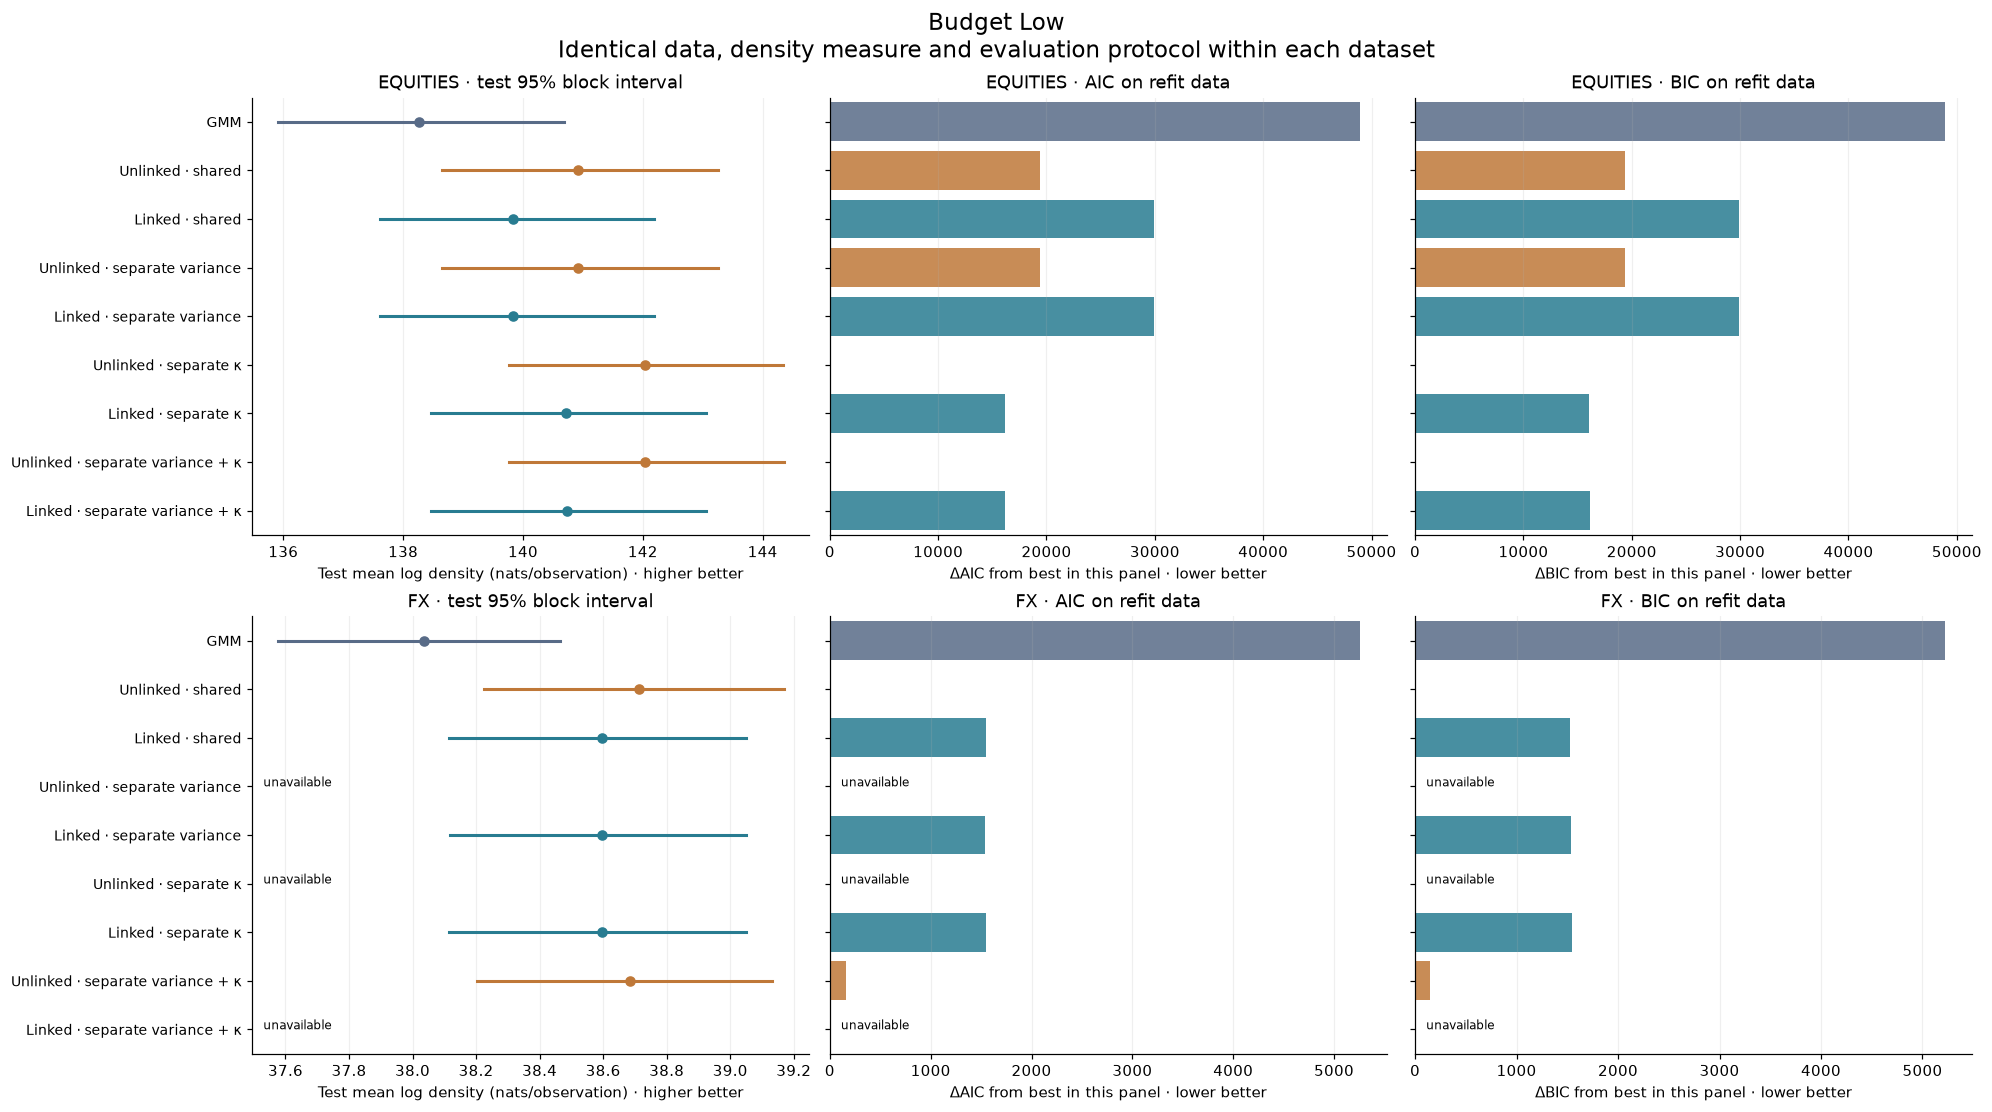

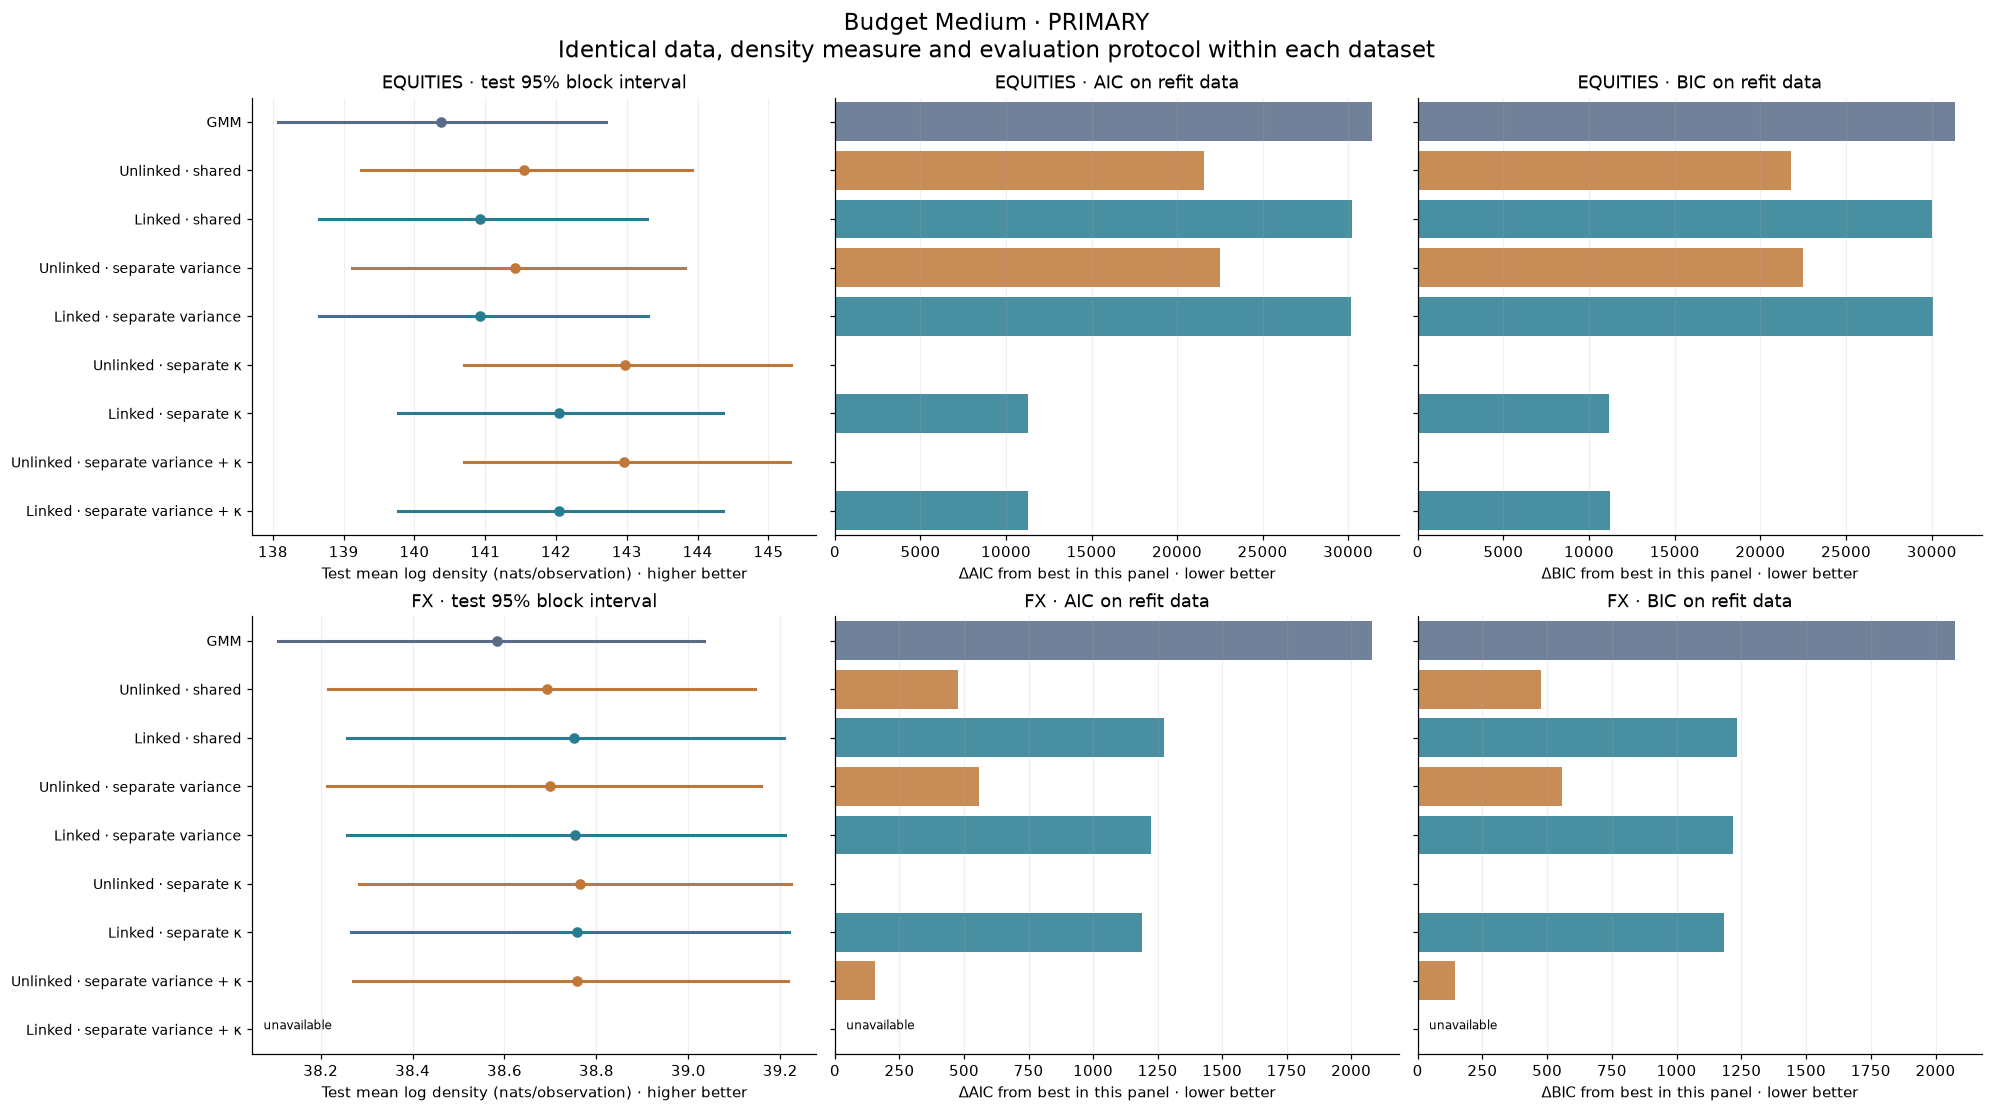

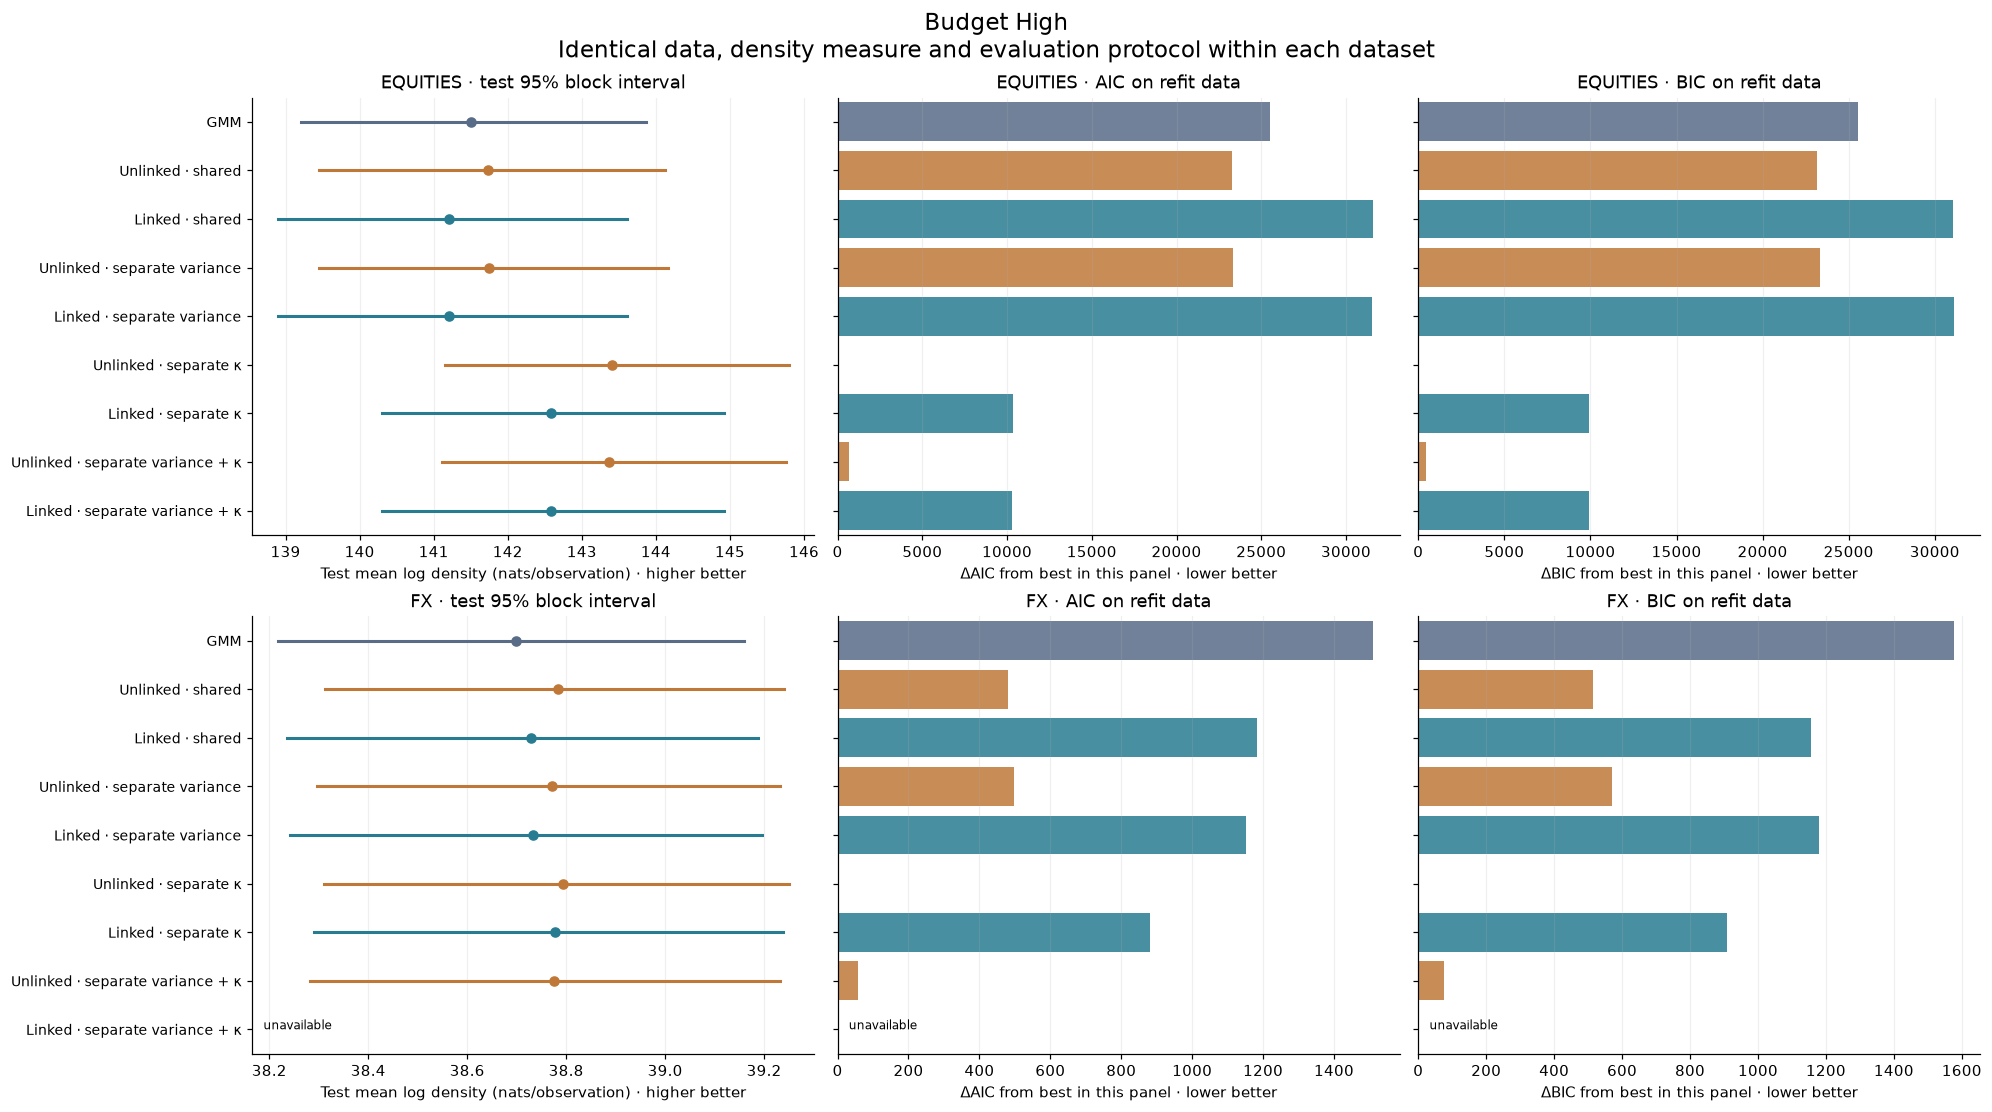

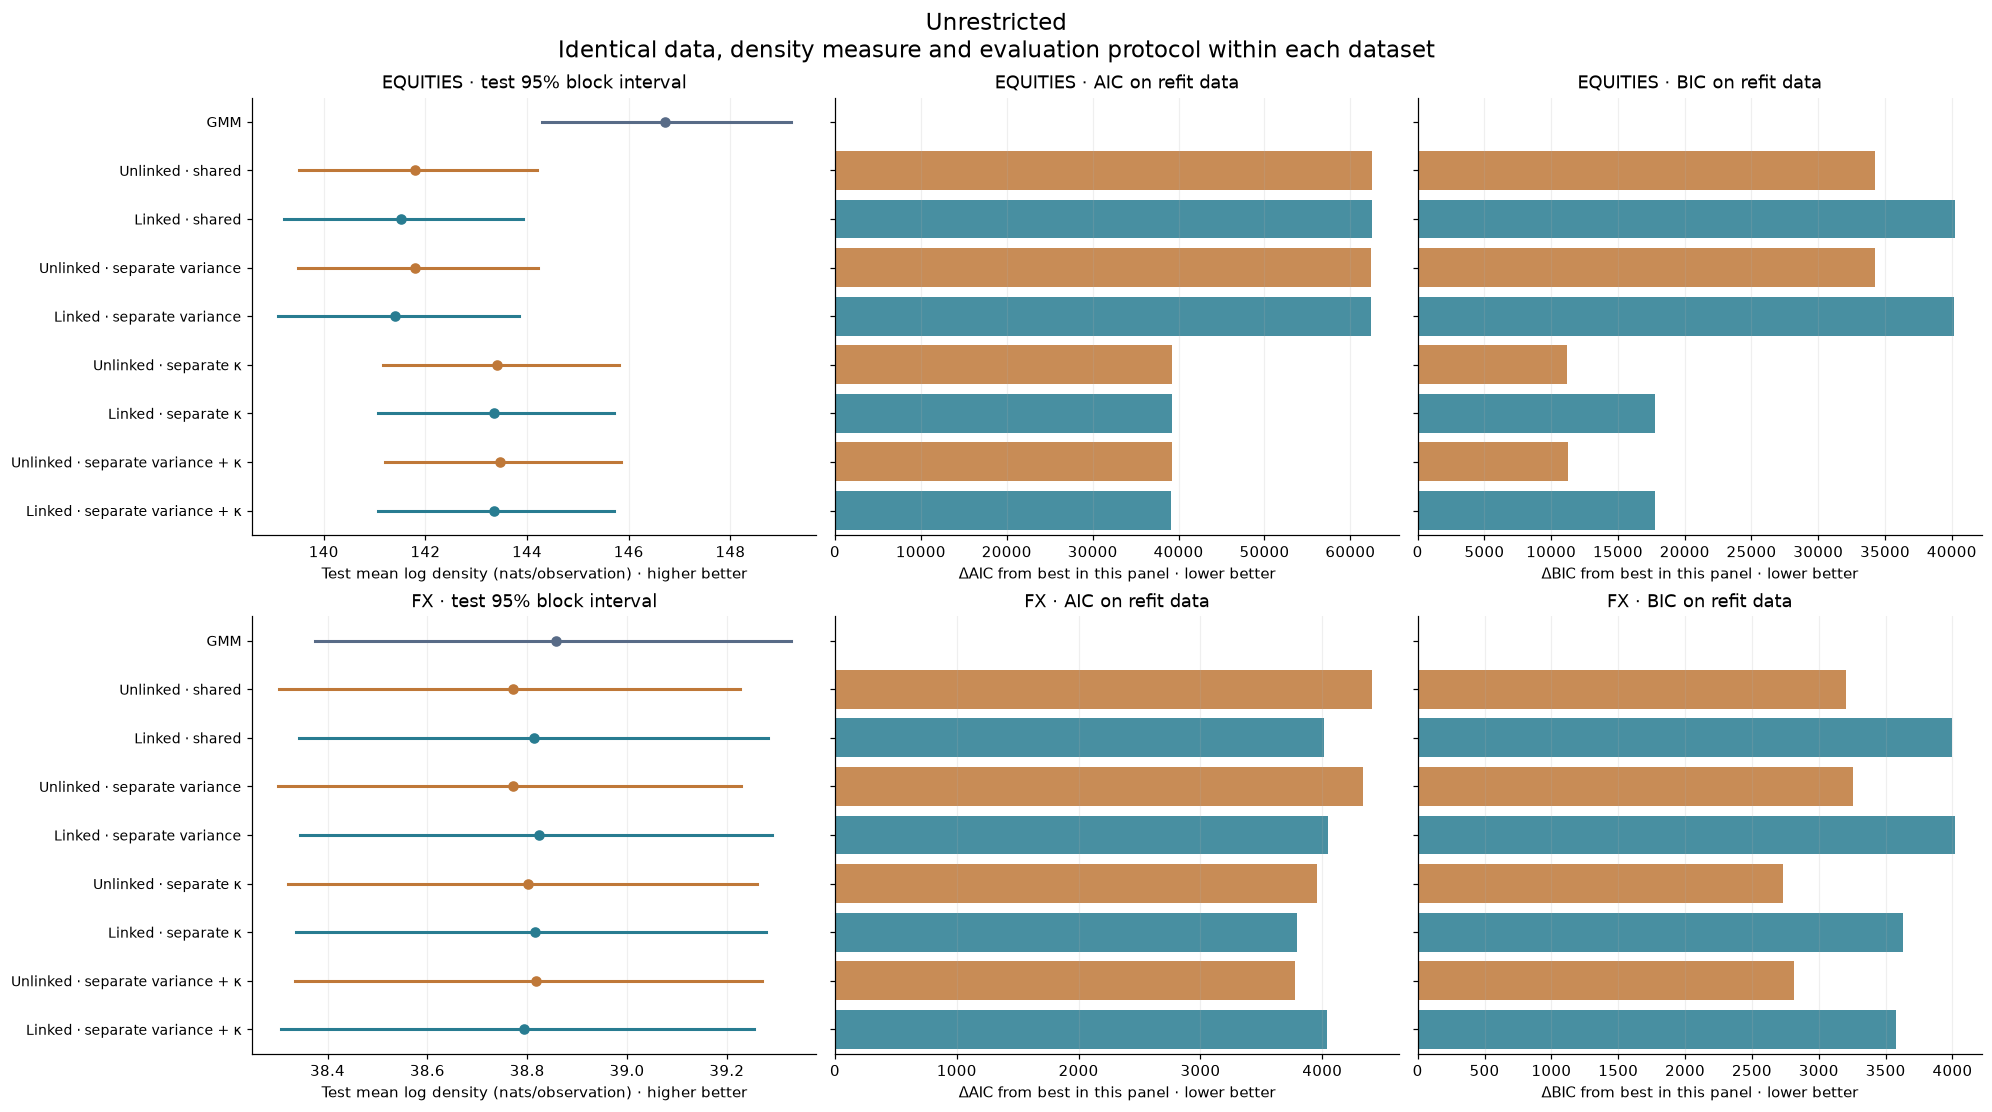

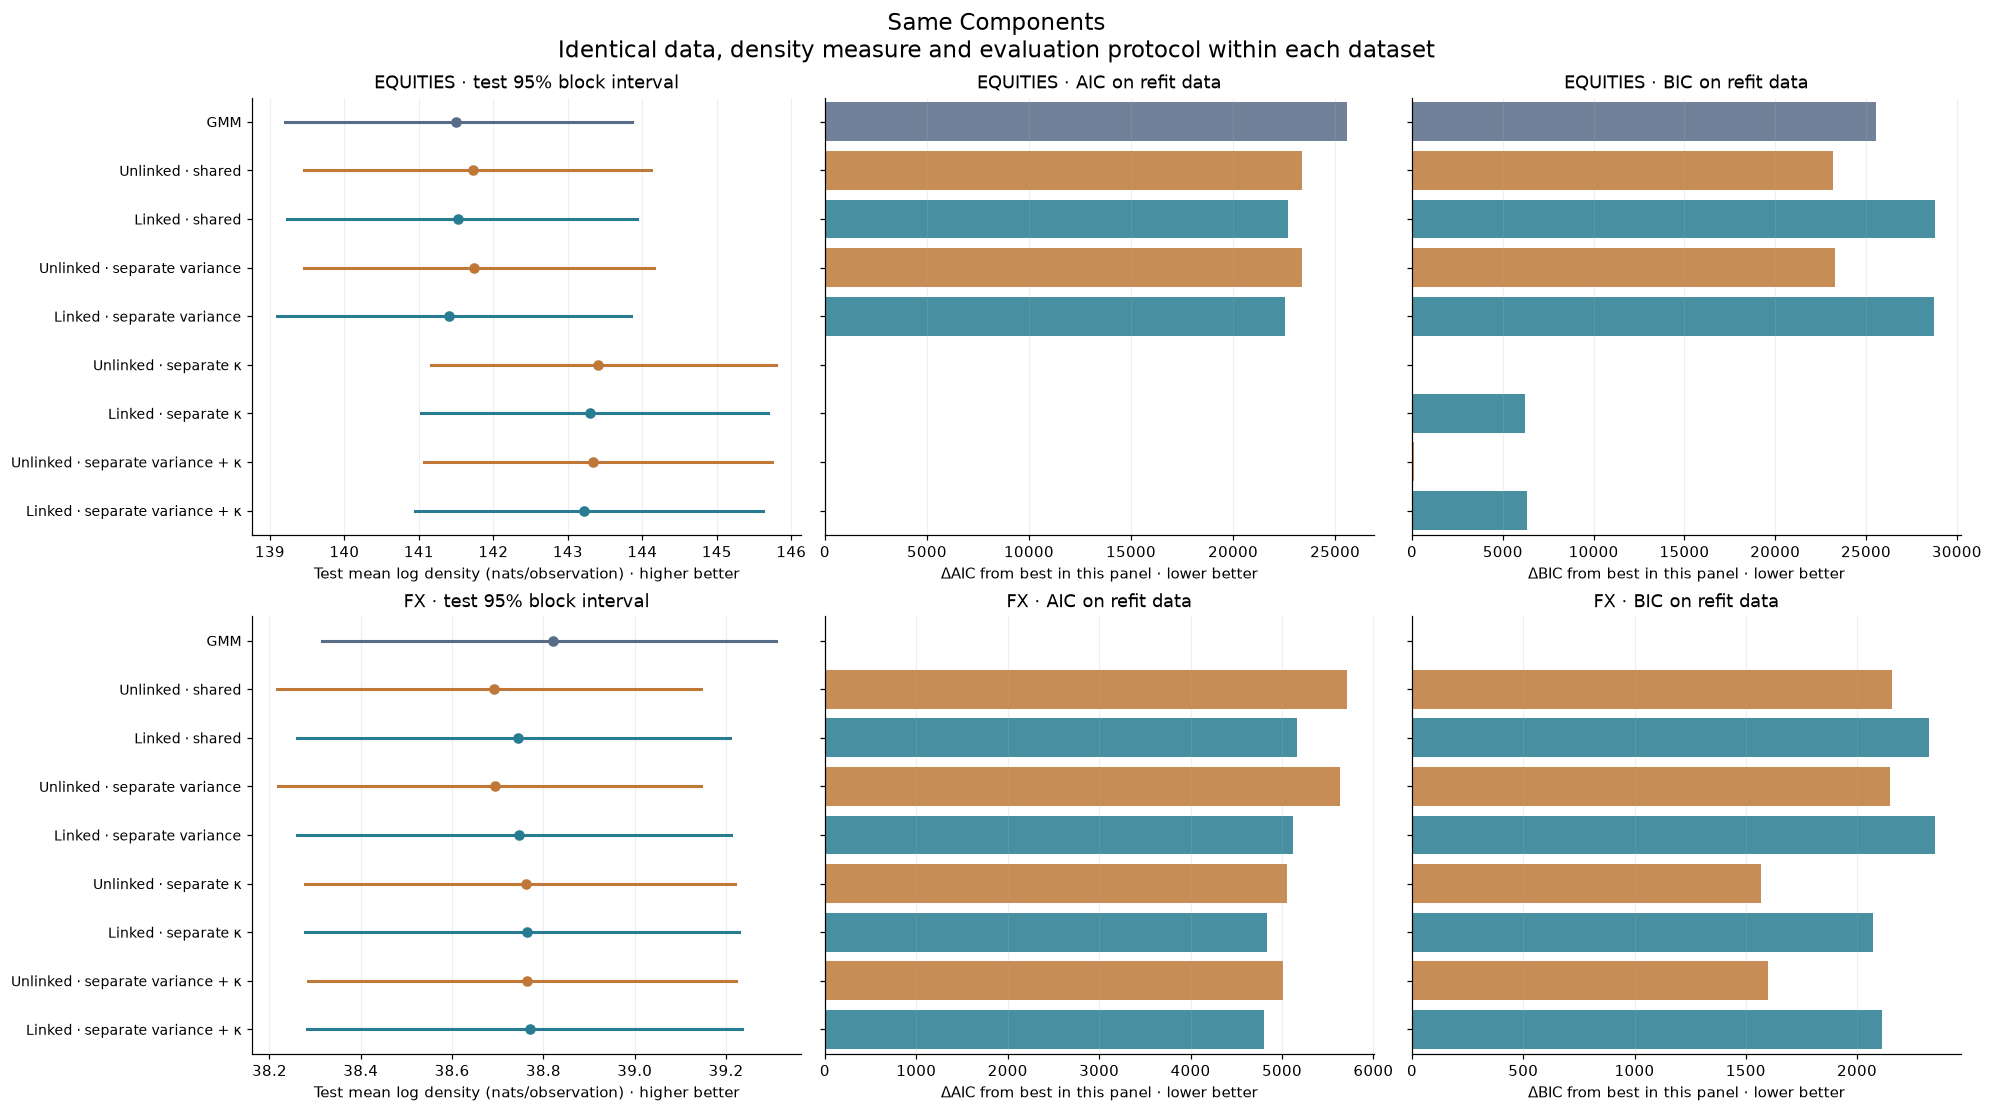

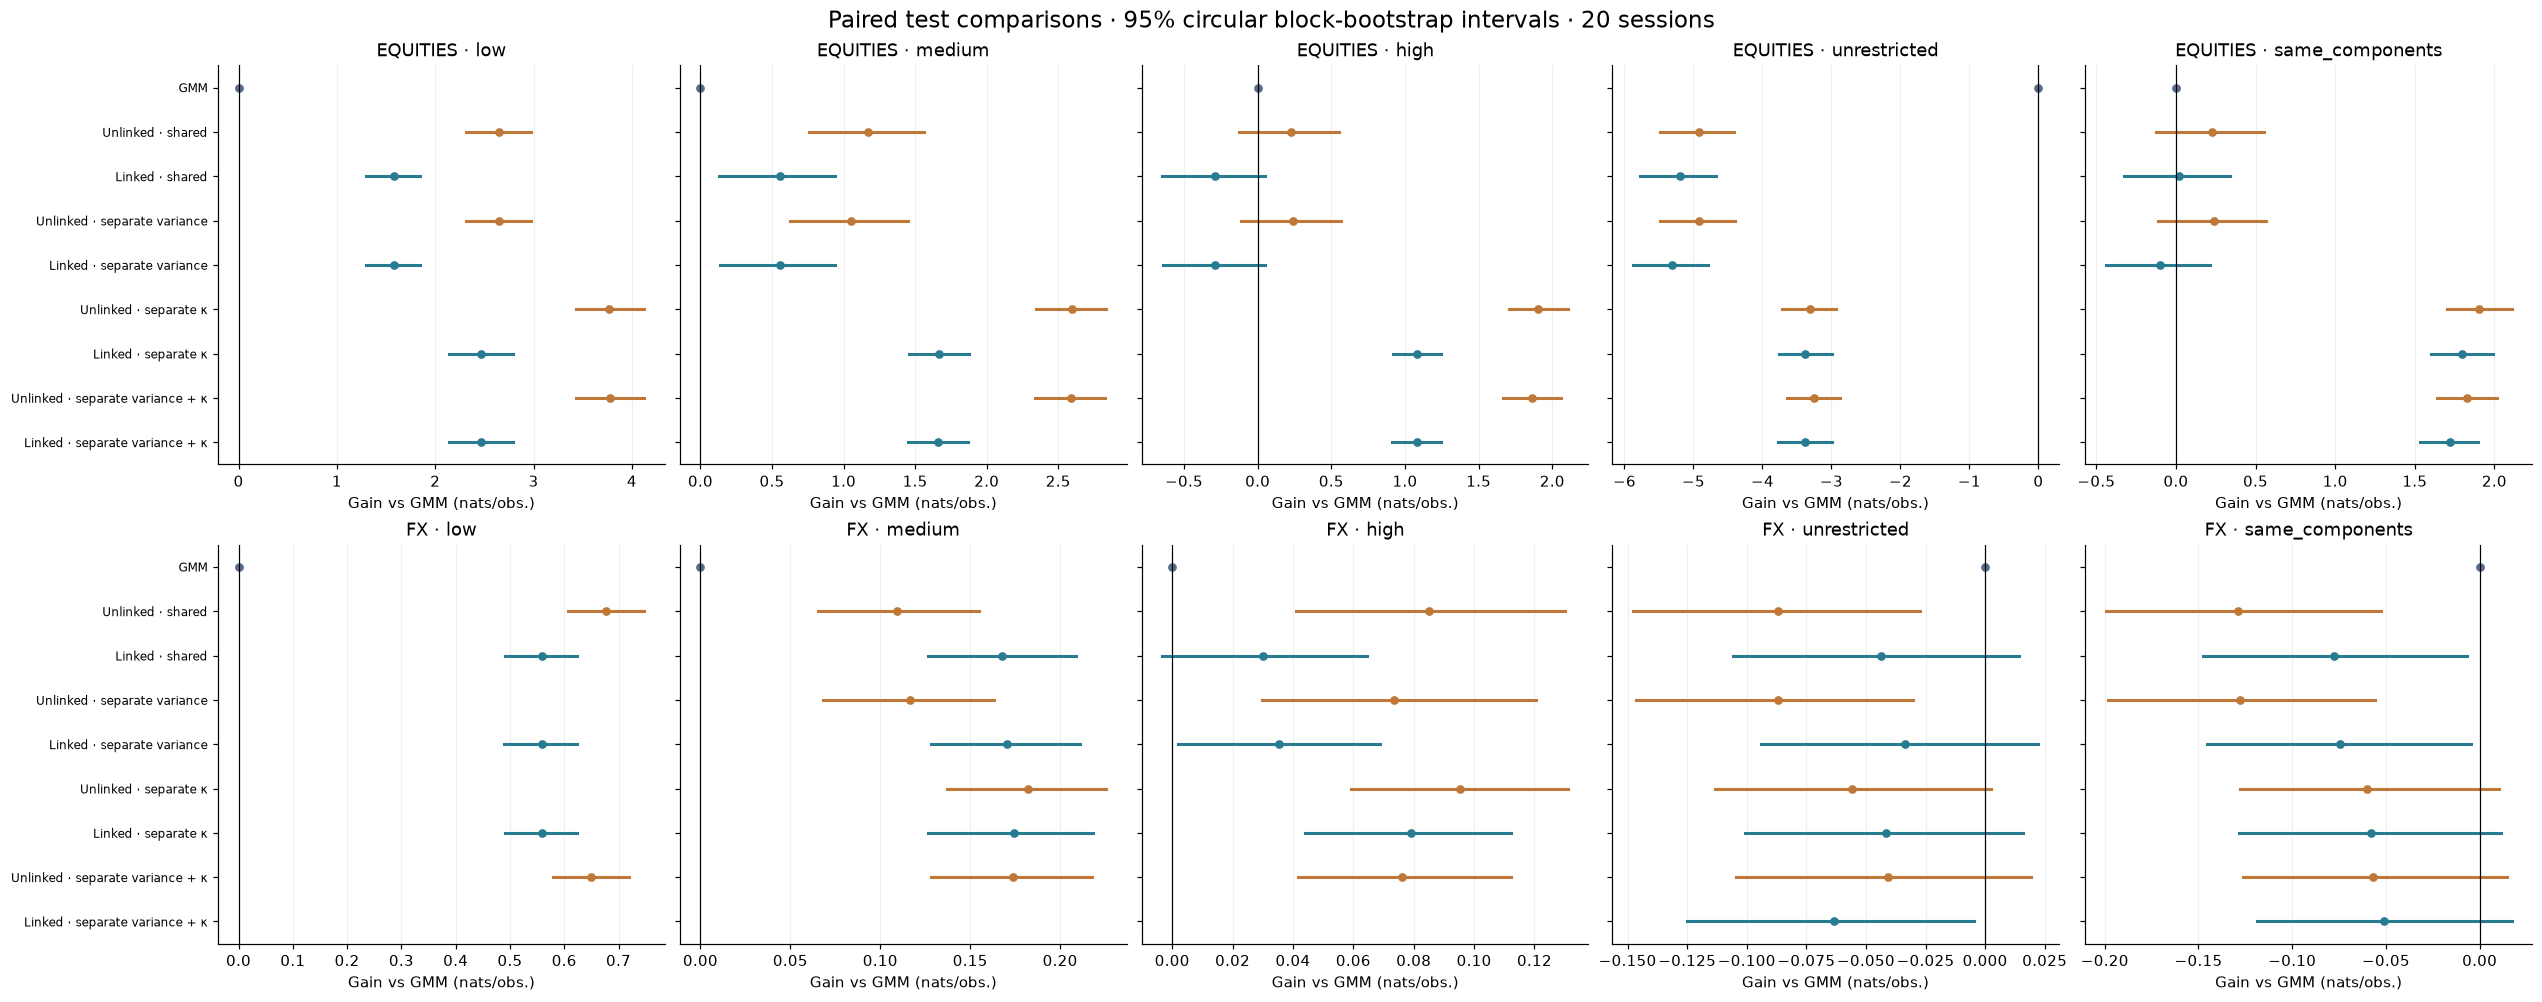

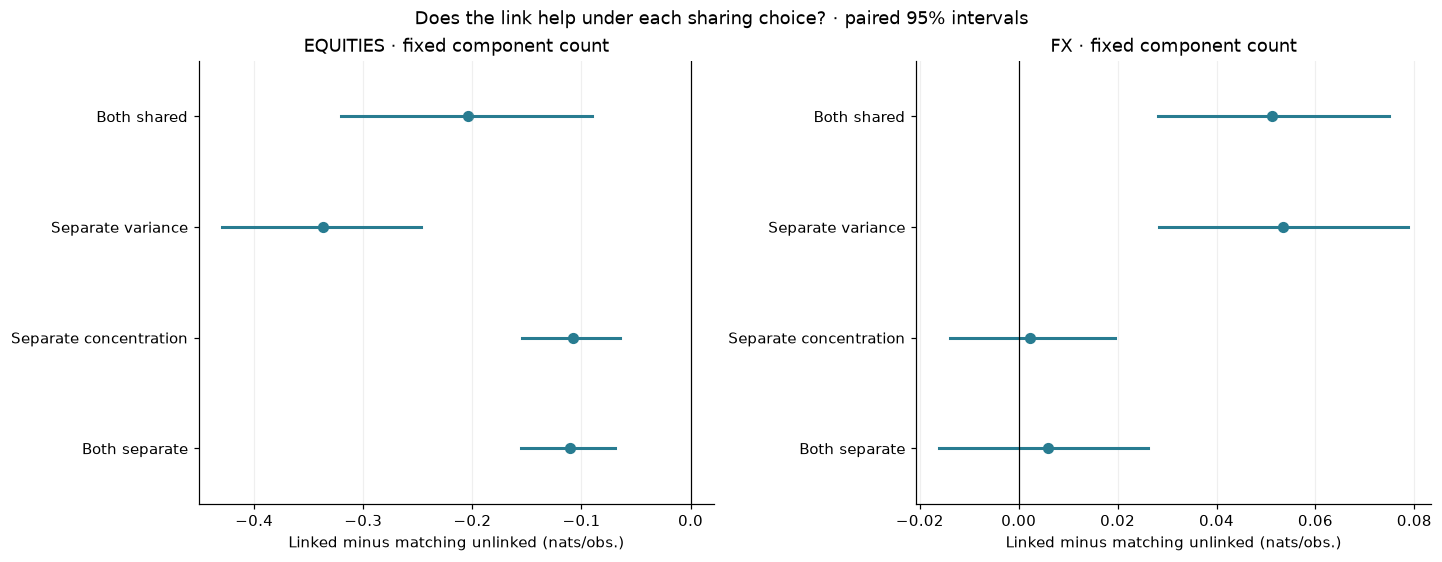

In [14]:
sharing_report.plots(sharing_results)

## 14. Validation performance and conclusions

The validation curves show the complete declared search, including the original GMM covariance and ridge alternatives. Test conclusions below summarize the predeclared medium budget. Other budgets and the same-component comparisons remain visible above to expose sensitivity.

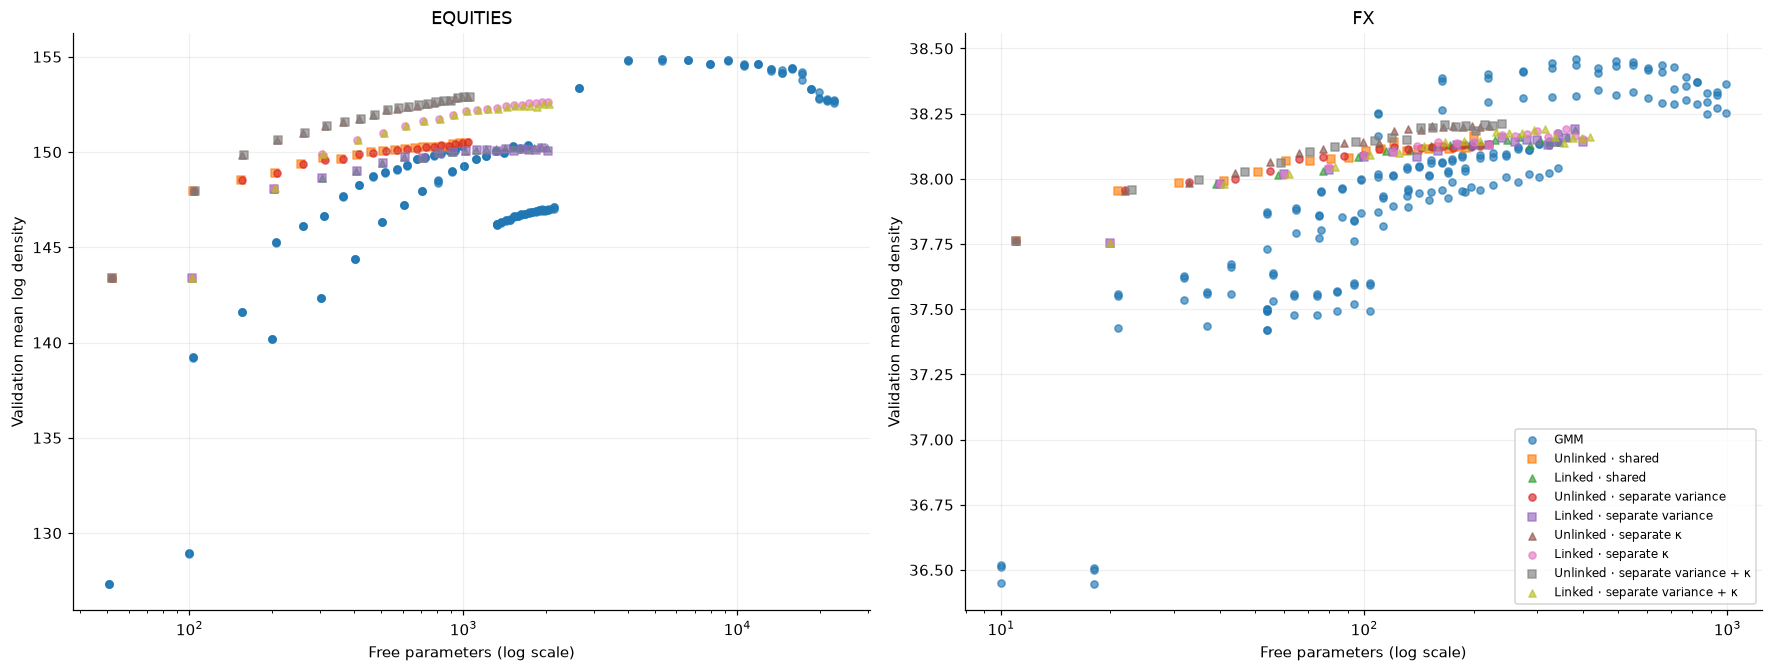

**EQUITIES.** The highest primary-budget test score is Unlinked / kappa_specific (K=12, 624 parameters): 142.9717 nats/observation. Its paired gain over GMM is +2.5970, with 95% interval [+2.3457, +2.8354]. On refit data, AIC favors Unlinked / both_specific; BIC favors Unlinked / kappa_specific. These criteria describe development fit and complexity; test likelihood evaluates the frozen models on later observations. With both spreads component-specific at K=19, the linked-minus-unlinked test gain is -0.1107 nats/observation, paired 95% interval [-0.1553, -0.0695].

**FX.** The highest primary-budget test score is Unlinked / kappa_specific (K=11, 121 parameters): 38.7654 nats/observation. Its paired gain over GMM is +0.1820, with 95% interval [+0.1370, +0.2256]. On refit data, AIC favors Unlinked / kappa_specific; BIC favors Unlinked / kappa_specific. These criteria describe development fit and complexity; test likelihood evaluates the frozen models on later observations. With both spreads component-specific at K=12, the linked-minus-unlinked test gain is +0.0059 nats/observation, paired 95% interval [-0.0160, +0.0261].

This is an exploratory follow-up using previously inspected test dates. Intervals condition on the fitted models, use 1,500 paired circular block replicates, and do not include refitting or selection uncertainty. The medium budget remains primary; other views are sensitivity comparisons. Confidence intervals are pointwise, not adjusted for all comparisons. AIC/BIC use nominal parameter counts and ordinary observation-count penalties; mixture singularities and serial dependence limit their classical interpretation.

Verified rows: 90
Figure exports: /Users/shashwatroy/VSCode Projects/Thesis/GMM/outputs/size_direction_sharing/figures


In [15]:
combined_trials=pd.concat([pd.read_csv(exp.OUTPUT/f'{name}_validation_trials.csv') for name in datasets]+[sharing_trials],ignore_index=True)
combined_trials.to_csv(sharing.OUT/'all_validation_trials.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(16,6),constrained_layout=True)
for ax,name in zip(axes,datasets):
    for index,family_name in enumerate(sharing_report.ORDER):
        points=combined_trials.loc[(combined_trials.dataset==name)&(combined_trials.family==family_name)&combined_trials.validation_mean_loglik.notna()]
        ax.scatter(points.parameters,points.validation_mean_loglik,label=sharing_report.LABELS[index],s=22,alpha=.65,marker=['o','s','^'][index%3])
    ax.set_xscale('log');ax.set_title(name.upper());ax.set_xlabel('Free parameters (log scale)');ax.set_ylabel('Validation mean log density');ax.grid(alpha=.2)
axes[1].legend(fontsize=8,loc='lower right')
fig.savefig(sharing.OUT/'figures'/'validation_vs_complexity.png',dpi=160)
plt.show()
display(Markdown(sharing_report.conclusions(sharing_results)))
print('Verified rows:',sharing_verification['comparison_rows'])
print('Figure exports:',sharing.OUT/'figures')